In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
from scipy.stats import spearmanr
import ast
from scipy.stats import ttest_ind
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator

## Scatter plots

In [2]:
def gen_scatter_plots(directory_data,directory_plots,data_list):
    warnings.filterwarnings('ignore')
    for data in data_list:
        # Get results
        df_sim_new = pd.read_csv(directory_data+data+'.tsv.gz', sep='\t')
            
        # Get name of model and of data used
        name_model = data.split("_")[:2][0]
        for name in data.split("_")[:2][1:]:
            name_model = name_model+"_"+name
        name_data = data.split("_")[2:][0]
        for name in data.split("_")[2:][1:]:
            name_data = name_data+"_"+name
        
        # Get mean response of the same point between samples
        df_sim_new["Point"] = df_sim_new["Cell"]+df_sim_new["Gene"]
        df_sim_new = df_sim_new[["Point","Log10 Prot. count","Prot. count predict"]].groupby("Point").mean()

        # Get scatter plot of protein count real vs prediction
        fig,ax=plt.subplots(1,1,figsize=(9, 8), dpi=400)
        ax.scatter(df_sim_new["Log10 Prot. count"], df_sim_new["Prot. count predict"], s=200, linewidth=2, color="darkblue",marker='*')
        ax.spines["bottom"].set_linewidth(4)
        ax.spines["left"].set_linewidth(4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.xaxis.set_tick_params(width=5, length=10)
        ax.yaxis.set_tick_params(width=5, length=10)
        ax.tick_params(axis='x', labelsize=25)
        ax.tick_params(axis='y', labelsize=25)
        plt.ylabel('Log10 Prot. count (predict)', fontsize=25)
        plt.xlabel('Log10 Prot. count', fontsize=25)
        plt.savefig(directory_plots +'Plot_'+data+'_prot_model.png', transparent=True, bbox_inches="tight")
        plt.close()
    warnings.filterwarnings('default')

## Evaluate performance models per cell

In [21]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator


# ----------------------------------------------------------------------------
# Dataset decoding
# Dataset names look like: {prefix}_{train_domain}_{split}[_{extra_test_set}]
# e.g. linear_immune_test_tissues  ->  domain="immune", rest="test_tissues"
# ----------------------------------------------------------------------------
# rest -> (split display, "evaluated on" display), per training domain
EVAL_INFO = {
    "immune": {
        "train":                ("Train",      "PBMCs"),
        "validation":           ("Validation", "PBMCs"),
        "test_tissues":         ("Test",       "Tissues"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
    "tissues": {
        "train":                ("Train",      "Tissues"),
        "validation":           ("Validation", "Tissues"),
        "test_immune":          ("Test",       "PBMCs"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
}

DOMAIN_TITLE = {
    "immune":  "Models trained on PBMCs (immune)",
    "tissues": "Models trained on tissues",
}
DOMAIN_SUFFIX = {"immune": "pbmcs", "tissues": "tissues"}

# One colour per model + one for the RNA-protein baseline
RNA_COLOR = "#D46A6A"   # muted red (same as before)
DEFAULT_MODEL_COLORS = ["#3B75AF", "#F2A541", "#5BA85B", "#8E6BB8", "#4DB6AC", "#A0522D"]


def _darken(color, factor=0.55):
    """Darker shade of a colour, used for box edges so collapsed boxes keep their hue."""
    r, g, b = mcolors.to_rgb(color)
    return (r * factor, g * factor, b * factor)


def _split_dataset(name):
    """'linear_immune_test_tissues' -> ('immune', 'test_tissues'); None if no match."""
    m = re.match(r"^(?:.*?_)?(immune|tissues)_(.+)$", name)
    return (m.group(1), m.group(2)) if m else (None, None)


def compare_spearmanr_by_domain(
    model_files,
    fig_prefix,
    model_colors=None,
    rna_from=None,
    show_points=True,
    ylim=(0, 1.0),
    figsize=(15, 7),
):
    """
    Plot SCC (data vs. model, and data vs. input RNA) for several model types,
    producing one figure per training domain (PBMCs / tissues).

    Parameters
    ----------
    model_files : dict {model label: csv path or DataFrame}
        Each table needs columns "Dataset", "Spearman prediction", "Spearman RNA".
    fig_prefix : str
        Output prefix. Saves f"{fig_prefix}_pbmcs.pdf" and f"{fig_prefix}_tissues.pdf".
    model_colors : dict {model label: colour}, optional
    rna_from : str, optional
        Model label whose "Spearman RNA" column is used for the baseline
        (the baseline doesn't depend on the model). Defaults to the first model.
    show_points : bool
        Overlay jittered per-sample points on each box.
    """
    # ---- load tables -------------------------------------------------------
    tables = {
        label: (pd.read_csv(src, sep='\t') if isinstance(src, (str, bytes)) or hasattr(src, "__fspath__") else src)
        for label, src in model_files.items()
    }
    labels = list(tables)
    if model_colors is None:
        model_colors = {l: DEFAULT_MODEL_COLORS[i % len(DEFAULT_MODEL_COLORS)] for i, l in enumerate(labels)}
    rna_from = rna_from or labels[0]

    # ---- style (matches the single-boxplot style, scaled for more boxes) ---
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })
    LW = 1.5
    rng = np.random.default_rng(0)

    # series drawn in each dataset group: RNA baseline first, then the models
    series = [("RNA baseline", RNA_COLOR)] + [(l, model_colors[l]) for l in labels]
    n_series = len(series)
    box_w = 0.8 / n_series          # boxes of one dataset fill 0.8 of a unit slot
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * box_w

    for domain in ["immune", "tissues"]:
        # datasets of this domain present in the data, in the fixed order
        present = set()
        for df in tables.values():
            for d in df["Dataset"].unique():
                dom, rest = _split_dataset(d)
                if dom == domain and rest in EVAL_INFO[domain]:
                    present.add(rest)
        rests = [r for r in EVAL_INFO[domain] if r in present]
        if not rests:
            continue

        def values(label, rest, col):
            df = tables[label]
            mask = df["Dataset"].map(lambda d: _split_dataset(d) == (domain, rest))
            return df.loc[mask, col].dropna().values

        fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=400)
        centers = np.arange(1, len(rests) + 1, dtype=float)

        for c, rest in zip(centers, rests):
            for (name, color), off in zip(series, offsets):
                if name == "RNA baseline":
                    vals = values(rna_from, rest, "Spearman RNA")
                else:
                    vals = values(name, rest, "Spearman prediction")
                if len(vals) == 0:
                    continue
                x = c + off
                edge = _darken(color)
                bp = ax.boxplot(
                    [vals], positions=[x], widths=box_w * 0.9,
                    patch_artist=True, showfliers=False, whis=1.5,
                    boxprops=dict(edgecolor=edge, linewidth=LW),
                    medianprops=dict(color="black", linewidth=1.3, zorder=5),
                    whiskerprops=dict(color=edge, linewidth=LW),
                    capprops=dict(color=edge, linewidth=LW),
                )
                box = bp["boxes"][0]
                box.set_facecolor(color)
                box.set_zorder(3)
                if name == "RNA baseline":
                    box.set_hatch("///")   # extra cue that survives very narrow boxes
                if show_points:
                    # raw points keep the colour visible even if the box collapses
                    jit = rng.uniform(-box_w * 0.3, box_w * 0.3, size=len(vals))
                    ax.scatter(x + jit, vals, s=12, facecolor=color, edgecolor=edge,
                               linewidth=0.5, alpha=0.7, zorder=4)

        # dotted separator between train/validation and held-out test sets
        first_test = next((i for i, r in enumerate(rests) if r.startswith("test")), None)
        if first_test:
            ax.axvline(centers[first_test] - 0.5, color="gray", linestyle=":", linewidth=1.5)

        # x ticks: two lines -> split / (evaluated on)
        tick_labels = [f"{EVAL_INFO[domain][r][0]}\n({EVAL_INFO[domain][r][1]})" for r in rests]
        ax.set_xticks(centers)
        ax.set_xticklabels(tick_labels, fontsize=17)
        ax.set_xlim(centers[0] - 0.55, centers[-1] + 0.55)

        # axes cosmetics (thick spines/ticks like the reference style)
        ax.set_ylim(*ylim)
        ax.yaxis.set_major_locator(MultipleLocator(0.2))
        ax.set_ylabel("Spearman correlation coefficient (SCC)", fontsize=20)
        ax.spines["bottom"].set_linewidth(4)
        ax.spines["left"].set_linewidth(4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.xaxis.set_tick_params(width=4, length=8)
        ax.yaxis.set_tick_params(width=4, length=8)
        ax.tick_params(axis="y", labelsize=17)

        ax.set_title(DOMAIN_TITLE[domain], fontsize=22, fontweight="bold", pad=18)

        # legend: RNA-protein baseline + one entry per model
        handles = [
            mpatches.Patch(facecolor=RNA_COLOR, edgecolor=_darken(RNA_COLOR), linewidth=LW,
                           hatch="///", label="RNA baseline (log10 protein vs log2 TPM)")
        ] + [
            mpatches.Patch(facecolor=model_colors[l], edgecolor=_darken(model_colors[l]),
                           linewidth=LW, label=l)
            for l in labels
        ]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
                  ncol=min(3, len(handles)), frameon=False, fontsize=15,
                  handlelength=1.4, handleheight=1.4)

        plt.tight_layout()
        plt.savefig(f"{fig_prefix}_{DOMAIN_SUFFIX[domain]}.pdf", transparent=True, bbox_inches="tight")
        plt.close(fig)


# ----------------------------------------------------------------------------
# Replaces the four separate compare_spearmanr(...) calls
# ----------------------------------------------------------------------------
if __name__ == "__main__":
    compare_spearmanr_by_domain(
        {
            "Constant model":                    "results/model_perf/cte_model_cell_mean.tsv.gz",
            "Linear model":                      "results/model_perf/lin_model_cell_mean.tsv.gz",
            "Linear (not gene-specific)":        "results/model_perf/lin_model_no_gene_specific_cell_mean.tsv.gz",
            "Linear (randomized gene-specific)": "results/model_perf/lin_model_rand_cell_mean.tsv.gz",
        },
        fig_prefix="figures/model_perf/all_models_scc",
    )

In [22]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches


# ----------------------------------------------------------------------------
# Dataset decoding
# Dataset names look like: {prefix}_{train_domain}_{split}[_{extra_test_set}]
# e.g. linear_immune_test_tissues  ->  domain="immune", rest="test_tissues"
# ----------------------------------------------------------------------------
# rest -> (split display, "evaluated on" display), per training domain
EVAL_INFO = {
    "immune": {
        "train":                ("Train",      "PBMCs"),
        "validation":           ("Validation", "PBMCs"),
        "test_tissues":         ("Test",       "Tissues"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
    "tissues": {
        "train":                ("Train",      "Tissues"),
        "validation":           ("Validation", "Tissues"),
        "test_immune":          ("Test",       "PBMCs"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
}

DOMAIN_TITLE = {
    "immune":  "Models trained on PBMCs (immune)",
    "tissues": "Models trained on tissues",
}
DOMAIN_SUFFIX = {"immune": "pbmcs", "tissues": "tissues"}

DEFAULT_MODEL_COLORS = ["#3B75AF", "#F2A541", "#5BA85B", "#8E6BB8", "#4DB6AC", "#A0522D"]


def _darken(color, factor=0.55):
    """Darker shade of a colour, used for box edges so collapsed boxes keep their hue."""
    r, g, b = mcolors.to_rgb(color)
    return (r * factor, g * factor, b * factor)


def _split_dataset(name):
    """'linear_immune_test_tissues' -> ('immune', 'test_tissues'); (None, None) if no match."""
    m = re.match(r"^(?:.*?_)?(immune|tissues)_(.+)$", name)
    return (m.group(1), m.group(2)) if m else (None, None)


def _find_mae_column(df):
    """Pick the MAE column: any column whose name contains 'mae', ignoring RNA ones."""
    cands = [c for c in df.columns if "mae" in c.lower() and "rna" not in c.lower()]
    if not cands:
        raise KeyError(
            f"No MAE column found. Columns are: {list(df.columns)}. "
            "Pass mae_col='<column name>'."
        )
    # prefer a 'prediction' column if several match
    cands.sort(key=lambda c: "pred" not in c.lower())
    return cands[0]


def compare_mae_by_domain(
    model_files,
    fig_prefix,
    model_colors=None,
    mae_col=None,
    show_points=True,
    ylim=None,
    figsize=(15, 7),
    ylabel="Mean absolute error (MAE)",
):
    """
    Plot MAE (data vs. model prediction) for several model types, producing one
    figure per training domain (PBMCs / tissues). There is no RNA baseline,
    since MAE is an error and RNA (log2 TPM) is not on the protein scale.

    Parameters
    ----------
    model_files : dict {model label: csv path or DataFrame}
        Each table needs a "Dataset" column and an MAE column.
    fig_prefix : str
        Output prefix. Saves f"{fig_prefix}_pbmcs.pdf" and f"{fig_prefix}_tissues.pdf".
    model_colors : dict {model label: colour}, optional
    mae_col : str, optional
        Name of the MAE column. If None, it is auto-detected (a column with "MAE"
        in its name, e.g. "MAE" or "MAE prediction").
    show_points : bool
        Overlay jittered per-sample points on each box.
    ylim : (float, float), optional
        Y-axis limits. Default: from 0 up to the data maximum (+ margin), shared
        by both domain figures so they are directly comparable.
    """
    # ---- load tables -------------------------------------------------------
    tables = {
        label: (pd.read_csv(src, sep='\t') if isinstance(src, (str, bytes)) or hasattr(src, "__fspath__") else src)
        for label, src in model_files.items()
    }
    labels = list(tables)
    if model_colors is None:
        model_colors = {l: DEFAULT_MODEL_COLORS[i % len(DEFAULT_MODEL_COLORS)] for i, l in enumerate(labels)}
    cols = {l: (mae_col or _find_mae_column(df)) for l, df in tables.items()}

    # ---- style (matches the single-boxplot style) --------------------------
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })
    LW = 1.5
    rng = np.random.default_rng(0)

    n_series = len(labels)
    box_w = 0.8 / n_series          # boxes of one dataset fill 0.8 of a unit slot
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * box_w

    def values(label, domain, rest):
        df = tables[label]
        mask = df["Dataset"].map(lambda d: _split_dataset(d) == (domain, rest))
        return df.loc[mask, cols[label]].dropna().values

    # shared y-limit across both figures (use the whiskers' reach, not outliers)
    if ylim is None:
        ymax = 0.0
        for l, df in tables.items():
            for d in df["Dataset"].unique():
                dom, rest = _split_dataset(d)
                if dom in EVAL_INFO and rest in EVAL_INFO[dom]:
                    v = values(l, dom, rest)
                    if len(v):
                        ymax = max(ymax, np.nanmax(v))
        ylim = (0, ymax * 1.05)

    for domain in ["immune", "tissues"]:
        # datasets of this domain present in the data, in the fixed order
        present = set()
        for df in tables.values():
            for d in df["Dataset"].unique():
                dom, rest = _split_dataset(d)
                if dom == domain and rest in EVAL_INFO[domain]:
                    present.add(rest)
        rests = [r for r in EVAL_INFO[domain] if r in present]
        if not rests:
            continue

        fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=400)
        centers = np.arange(1, len(rests) + 1, dtype=float)

        for c, rest in zip(centers, rests):
            for label, off in zip(labels, offsets):
                vals = values(label, domain, rest)
                if len(vals) == 0:
                    continue
                color = model_colors[label]
                edge = _darken(color)
                x = c + off
                bp = ax.boxplot(
                    [vals], positions=[x], widths=box_w * 0.9,
                    patch_artist=True, showfliers=False, whis=1.5,
                    boxprops=dict(edgecolor=edge, linewidth=LW),
                    medianprops=dict(color="black", linewidth=1.3, zorder=5),
                    whiskerprops=dict(color=edge, linewidth=LW),
                    capprops=dict(color=edge, linewidth=LW),
                )
                box = bp["boxes"][0]
                box.set_facecolor(color)
                box.set_zorder(3)
                if show_points:
                    # raw points keep the colour visible even if the box collapses
                    jit = rng.uniform(-box_w * 0.3, box_w * 0.3, size=len(vals))
                    ax.scatter(x + jit, vals, s=12, facecolor=color, edgecolor=edge,
                               linewidth=0.5, alpha=0.7, zorder=4)

        # dotted separator between train/validation and held-out test sets
        first_test = next((i for i, r in enumerate(rests) if r.startswith("test")), None)
        if first_test:
            ax.axvline(centers[first_test] - 0.5, color="gray", linestyle=":", linewidth=1.5)

        # x ticks: two lines -> split / (evaluated on)
        tick_labels = [f"{EVAL_INFO[domain][r][0]}\n({EVAL_INFO[domain][r][1]})" for r in rests]
        ax.set_xticks(centers)
        ax.set_xticklabels(tick_labels, fontsize=17)
        ax.set_xlim(centers[0] - 0.55, centers[-1] + 0.55)

        # axes cosmetics (thick spines/ticks like the reference style)
        ax.set_ylim(*ylim)
        ax.set_ylabel(ylabel, fontsize=20)
        ax.spines["bottom"].set_linewidth(4)
        ax.spines["left"].set_linewidth(4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.xaxis.set_tick_params(width=4, length=8)
        ax.yaxis.set_tick_params(width=4, length=8)
        ax.tick_params(axis="y", labelsize=17)

        ax.set_title(DOMAIN_TITLE[domain], fontsize=22, fontweight="bold", pad=18)

        # legend: one entry per model
        handles = [
            mpatches.Patch(facecolor=model_colors[l], edgecolor=_darken(model_colors[l]),
                           linewidth=LW, label=l)
            for l in labels
        ]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
                  ncol=min(4, len(handles)), frameon=False, fontsize=15,
                  handlelength=1.4, handleheight=1.4)

        plt.tight_layout()
        plt.savefig(f"{fig_prefix}_{DOMAIN_SUFFIX[domain]}.pdf", transparent=True, bbox_inches="tight")
        plt.close(fig)


# ----------------------------------------------------------------------------
# Replaces the four separate per-model MAE calls
# ----------------------------------------------------------------------------
if __name__ == "__main__":
    compare_mae_by_domain(
        {
            "Constant model":                    "results/model_perf/cte_model_cell_mean.tsv.gz",
            "Linear model":                      "results/model_perf/lin_model_cell_mean.tsv.gz",
            "Linear (not gene-specific)":        "results/model_perf/lin_model_no_gene_specific_cell_mean.tsv.gz",
            "Linear (randomized gene-specific)": "results/model_perf/lin_model_rand_cell_mean.tsv.gz",
        },
        fig_prefix="figures/model_perf/all_models_MAE",
    )

# Get performance per gene

In [1097]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator


# ----------------------------------------------------------------------------
# Dataset decoding
# Dataset names look like: {prefix}_{train_domain}_{split}[_{extra_test_set}]
# e.g. linear_immune_test_tissues  ->  domain="immune", rest="test_tissues"
# ----------------------------------------------------------------------------
# rest -> (split display, "evaluated on" display), per training domain
EVAL_INFO = {
    "immune": {
        "train":                ("Train",      "PBMCs"),
        "validation":           ("Validation", "PBMCs"),
        "test_tissues":         ("Test",       "Tissues"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
    "tissues": {
        "train":                ("Train",      "Tissues"),
        "validation":           ("Validation", "Tissues"),
        "test_immune":          ("Test",       "PBMCs"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
}

DOMAIN_TITLE = {
    "immune":  "Models trained on PBMCs (immune)",
    "tissues": "Models trained on tissues",
}
DOMAIN_SUFFIX = {"immune": "pbmcs", "tissues": "tissues"}

# One colour per model (the first one is yellow, as the gene-specific linear model in the other plots)
DEFAULT_MODEL_COLORS = ["#F2A541", "#3B75AF", "#5BA85B", "#8E6BB8", "#4DB6AC", "#A0522D"]


def _darken(color, factor=0.55):
    """Darker shade of a colour, used for box edges so collapsed boxes keep their hue."""
    r, g, b = mcolors.to_rgb(color)
    return (r * factor, g * factor, b * factor)


def _split_dataset(name):
    """'linear_immune_test_tissues' -> ('immune', 'test_tissues'); None if no match."""
    m = re.match(r"^(?:.*?_)?(immune|tissues)_(.+)$", name)
    return (m.group(1), m.group(2)) if m else (None, None)


def compare_spearmanr_by_domain(
    model_files,
    fig_prefix,
    model_colors=None,
    show_points=True,
    ylim=(0, 1.0),
    figsize=None,
    exclude_splits=("validation",),
):
    """
    Plot SCC (data vs. model prediction) per training domain (PBMCs / tissues).
    SCC is computed per gene, so all benchmark models share the value of the gene-specific
    linear model: pass only that one, e.g. {"Linear model": table}. With a single model the
    legend is left out and the figure is narrow; with several models it works as before.

    Parameters
    ----------
    model_files : dict {model label: csv path or DataFrame}
        Each table needs columns "Dataset" and "Spearman prediction".
    fig_prefix : str
        Output prefix. Saves f"{fig_prefix}_pbmcs.pdf" and f"{fig_prefix}_tissues.pdf".
    model_colors : dict {model label: colour}, optional
        Default: the first model is yellow ("#F2A541", the colour of the gene-specific linear model).
    show_points : bool
        Overlay jittered per-sample points on each box.
    figsize : (float, float), optional
        Default: width scales with the number of dataset groups (narrower for a single model).
    exclude_splits : tuple of str
        Splits left out of the plot (default: validation, too few samples for a meaningful SCC).
    """
    # ---- load tables -------------------------------------------------------
    tables = {
        label: (pd.read_csv(src, sep='\t') if isinstance(src, (str, bytes)) or hasattr(src, "__fspath__") else src)
        for label, src in model_files.items()
    }
    labels = list(tables)
    if model_colors is None:
        model_colors = {l: DEFAULT_MODEL_COLORS[i % len(DEFAULT_MODEL_COLORS)] for i, l in enumerate(labels)}

    # ---- style (matches the single-boxplot style, scaled for more boxes) ---
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })
    LW = 1.5
    rng = np.random.default_rng(0)

    # series drawn in each dataset group: one per model
    series = [(l, model_colors[l]) for l in labels]
    n_series = len(series)
    box_w = 0.8 / n_series          # boxes of one dataset fill 0.8 of a unit slot
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * box_w

    for domain in ["immune", "tissues"]:
        # datasets of this domain present in the data, in the fixed order
        present = set()
        for df in tables.values():
            for d in df["Dataset"].unique():
                dom, rest = _split_dataset(d)
                if dom == domain and rest in EVAL_INFO[domain]:
                    present.add(rest)
        rests = [r for r in EVAL_INFO[domain] if r in present and r not in exclude_splits]
        if not rests:
            continue

        def values(label, rest, col):
            df = tables[label]
            mask = df["Dataset"].map(lambda d: _split_dataset(d) == (domain, rest))
            return df.loc[mask, col].dropna().values

        # inches per dataset group (+ room for the y-axis labels): narrow when there is a single box per group
        fs = figsize or ((2.1 if n_series == 1 else 3.1) * len(rests) + 1.5, 6.5)
        fig, ax = plt.subplots(1, 1, figsize=fs, dpi=400)
        centers = np.arange(1, len(rests) + 1, dtype=float)

        for c, rest in zip(centers, rests):
            for (name, color), off in zip(series, offsets):
                vals = values(name, rest, "Spearman prediction")
                if len(vals) == 0:
                    continue
                x = c + off
                edge = _darken(color)
                bp = ax.boxplot(
                    [vals], positions=[x], widths=box_w * 0.9,
                    patch_artist=True, showfliers=False, whis=1.5,
                    boxprops=dict(edgecolor=edge, linewidth=LW),
                    medianprops=dict(color="black", linewidth=1.3, zorder=5),
                    whiskerprops=dict(color=edge, linewidth=LW),
                    capprops=dict(color=edge, linewidth=LW),
                )
                box = bp["boxes"][0]
                box.set_facecolor(color)
                box.set_zorder(3)
                if show_points:
                    # raw points keep the colour visible even if the box collapses
                    jit = rng.uniform(-box_w * 0.3, box_w * 0.3, size=len(vals))
                    ax.scatter(x + jit, vals, s=12, facecolor=color, edgecolor=edge,
                               linewidth=0.5, alpha=0.7, zorder=4)

        # dotted separator between train/validation and held-out test sets
        first_test = next((i for i, r in enumerate(rests) if r.startswith("test")), None)
        if first_test:
            ax.axvline(centers[first_test] - 0.5, color="gray", linestyle=":", linewidth=1.5)

        # x ticks: two lines -> split / (evaluated on)
        tick_labels = [f"{EVAL_INFO[domain][r][0]}\n({EVAL_INFO[domain][r][1]})" for r in rests]
        ax.set_xticks(centers)
        ax.set_xticklabels(tick_labels, fontsize=17)
        ax.set_xlim(centers[0] - 0.5, centers[-1] + 0.5)

        # axes cosmetics (thick spines/ticks like the reference style)
        ax.set_ylim(*ylim)
        ax.yaxis.set_major_locator(MultipleLocator(0.2))
        ax.set_ylabel("Spearman correlation coefficient (SCC)", fontsize=20)
        ax.spines["bottom"].set_linewidth(4)
        ax.spines["left"].set_linewidth(4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.xaxis.set_tick_params(width=4, length=8)
        ax.yaxis.set_tick_params(width=4, length=8)
        ax.tick_params(axis="y", labelsize=17)

        ax.set_title(DOMAIN_TITLE[domain], fontsize=22, fontweight="bold", pad=18)

        # legend: one entry per model (not needed for a single model)
        handles = [
            mpatches.Patch(facecolor=model_colors[l], edgecolor=_darken(model_colors[l]),
                           linewidth=LW, label=l)
            for l in labels
        ]
        if n_series > 1:
            ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
                      ncol=2, frameon=False, fontsize=15,
                      handlelength=1.4, handleheight=1.4)

        plt.tight_layout()
        plt.savefig(f"{fig_prefix}_{DOMAIN_SUFFIX[domain]}.pdf", transparent=True, bbox_inches="tight")
        plt.close(fig)


# ----------------------------------------------------------------------------
# SCC per gene: only the gene-specific linear model (the benchmarks have the same SCC)
# ----------------------------------------------------------------------------
if __name__ == "__main__":
    compare_spearmanr_by_domain(
        {"Linear model": "results/model_perf/per_gene/lin_model_gene_mean.tsv.gz"},
        fig_prefix="figures/model_perf/per_gene/all_models_scc",
    )

In [25]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches


# ----------------------------------------------------------------------------
# Dataset decoding
# Dataset names look like: {prefix}_{train_domain}_{split}[_{extra_test_set}]
# e.g. linear_immune_test_tissues  ->  domain="immune", rest="test_tissues"
# ----------------------------------------------------------------------------
# rest -> (split display, "evaluated on" display), per training domain
EVAL_INFO = {
    "immune": {
        "train":                ("Train",      "PBMCs"),
        "validation":           ("Validation", "PBMCs"),
        "test_tissues":         ("Test",       "Tissues"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
    "tissues": {
        "train":                ("Train",      "Tissues"),
        "validation":           ("Validation", "Tissues"),
        "test_immune":          ("Test",       "PBMCs"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
}

DOMAIN_TITLE = {
    "immune":  "Models trained on PBMCs (immune)",
    "tissues": "Models trained on tissues",
}
DOMAIN_SUFFIX = {"immune": "pbmcs", "tissues": "tissues"}

DEFAULT_MODEL_COLORS = ["#3B75AF", "#F2A541", "#5BA85B", "#8E6BB8", "#4DB6AC", "#A0522D"]


def _darken(color, factor=0.55):
    """Darker shade of a colour, used for box edges so collapsed boxes keep their hue."""
    r, g, b = mcolors.to_rgb(color)
    return (r * factor, g * factor, b * factor)


def _split_dataset(name):
    """'linear_immune_test_tissues' -> ('immune', 'test_tissues'); (None, None) if no match."""
    m = re.match(r"^(?:.*?_)?(immune|tissues)_(.+)$", name)
    return (m.group(1), m.group(2)) if m else (None, None)


def _find_mae_column(df):
    """Pick the MAE column: any column whose name contains 'mae', ignoring RNA ones."""
    cands = [c for c in df.columns if "mae" in c.lower() and "rna" not in c.lower()]
    if not cands:
        raise KeyError(
            f"No MAE column found. Columns are: {list(df.columns)}. "
            "Pass mae_col='<column name>'."
        )
    # prefer a 'prediction' column if several match
    cands.sort(key=lambda c: "pred" not in c.lower())
    return cands[0]


def compare_mae_by_domain(
    model_files,
    fig_prefix,
    model_colors=None,
    mae_col=None,
    show_points=True,
    ylim=None,
    figsize=(15, 7),
    ylabel="Mean absolute error (MAE)",
):
    """
    Plot MAE (data vs. model prediction) for several model types, producing one
    figure per training domain (PBMCs / tissues). There is no RNA baseline,
    since MAE is an error and RNA (log2 TPM) is not on the protein scale.

    Parameters
    ----------
    model_files : dict {model label: csv path or DataFrame}
        Each table needs a "Dataset" column and an MAE column.
    fig_prefix : str
        Output prefix. Saves f"{fig_prefix}_pbmcs.pdf" and f"{fig_prefix}_tissues.pdf".
    model_colors : dict {model label: colour}, optional
    mae_col : str, optional
        Name of the MAE column. If None, it is auto-detected (a column with "MAE"
        in its name, e.g. "MAE" or "MAE prediction").
    show_points : bool
        Overlay jittered per-sample points on each box.
    ylim : (float, float), optional
        Y-axis limits. Default: from 0 up to the data maximum (+ margin), shared
        by both domain figures so they are directly comparable.
    """
    # ---- load tables -------------------------------------------------------
    tables = {
        label: (pd.read_csv(src, sep='\t') if isinstance(src, (str, bytes)) or hasattr(src, "__fspath__") else src)
        for label, src in model_files.items()
    }
    labels = list(tables)
    if model_colors is None:
        model_colors = {l: DEFAULT_MODEL_COLORS[i % len(DEFAULT_MODEL_COLORS)] for i, l in enumerate(labels)}
    cols = {l: (mae_col or _find_mae_column(df)) for l, df in tables.items()}

    # ---- style (matches the single-boxplot style) --------------------------
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })
    LW = 1.5
    rng = np.random.default_rng(0)

    n_series = len(labels)
    box_w = 0.8 / n_series          # boxes of one dataset fill 0.8 of a unit slot
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * box_w

    def values(label, domain, rest):
        df = tables[label]
        mask = df["Dataset"].map(lambda d: _split_dataset(d) == (domain, rest))
        return df.loc[mask, cols[label]].dropna().values

    # shared y-limit across both figures (use the whiskers' reach, not outliers)
    if ylim is None:
        ymax = 0.0
        for l, df in tables.items():
            for d in df["Dataset"].unique():
                dom, rest = _split_dataset(d)
                if dom in EVAL_INFO and rest in EVAL_INFO[dom]:
                    v = values(l, dom, rest)
                    if len(v):
                        ymax = max(ymax, np.nanmax(v))
        ylim = (0, ymax * 1.05)

    for domain in ["immune", "tissues"]:
        # datasets of this domain present in the data, in the fixed order
        present = set()
        for df in tables.values():
            for d in df["Dataset"].unique():
                dom, rest = _split_dataset(d)
                if dom == domain and rest in EVAL_INFO[domain]:
                    present.add(rest)
        rests = [r for r in EVAL_INFO[domain] if r in present]
        if not rests:
            continue

        fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=400)
        centers = np.arange(1, len(rests) + 1, dtype=float)

        for c, rest in zip(centers, rests):
            for label, off in zip(labels, offsets):
                vals = values(label, domain, rest)
                if len(vals) == 0:
                    continue
                color = model_colors[label]
                edge = _darken(color)
                x = c + off
                bp = ax.boxplot(
                    [vals], positions=[x], widths=box_w * 0.9,
                    patch_artist=True, showfliers=False, whis=1.5,
                    boxprops=dict(edgecolor=edge, linewidth=LW),
                    medianprops=dict(color="black", linewidth=1.3, zorder=5),
                    whiskerprops=dict(color=edge, linewidth=LW),
                    capprops=dict(color=edge, linewidth=LW),
                )
                box = bp["boxes"][0]
                box.set_facecolor(color)
                box.set_zorder(3)
                if show_points:
                    # raw points keep the colour visible even if the box collapses
                    jit = rng.uniform(-box_w * 0.3, box_w * 0.3, size=len(vals))
                    ax.scatter(x + jit, vals, s=12, facecolor=color, edgecolor=edge,
                               linewidth=0.5, alpha=0.7, zorder=4)

        # dotted separator between train/validation and held-out test sets
        first_test = next((i for i, r in enumerate(rests) if r.startswith("test")), None)
        if first_test:
            ax.axvline(centers[first_test] - 0.5, color="gray", linestyle=":", linewidth=1.5)

        # x ticks: two lines -> split / (evaluated on)
        tick_labels = [f"{EVAL_INFO[domain][r][0]}\n({EVAL_INFO[domain][r][1]})" for r in rests]
        ax.set_xticks(centers)
        ax.set_xticklabels(tick_labels, fontsize=17)
        ax.set_xlim(centers[0] - 0.55, centers[-1] + 0.55)

        # axes cosmetics (thick spines/ticks like the reference style)
        ax.set_ylim(*ylim)
        ax.set_ylabel(ylabel, fontsize=20)
        ax.spines["bottom"].set_linewidth(4)
        ax.spines["left"].set_linewidth(4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.xaxis.set_tick_params(width=4, length=8)
        ax.yaxis.set_tick_params(width=4, length=8)
        ax.tick_params(axis="y", labelsize=17)

        ax.set_title(DOMAIN_TITLE[domain], fontsize=22, fontweight="bold", pad=18)

        # legend: one entry per model
        handles = [
            mpatches.Patch(facecolor=model_colors[l], edgecolor=_darken(model_colors[l]),
                           linewidth=LW, label=l)
            for l in labels
        ]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
                  ncol=min(4, len(handles)), frameon=False, fontsize=15,
                  handlelength=1.4, handleheight=1.4)

        plt.tight_layout()
        plt.savefig(f"{fig_prefix}_{DOMAIN_SUFFIX[domain]}.pdf", transparent=True, bbox_inches="tight")
        plt.close(fig)


# ----------------------------------------------------------------------------
# Replaces the four separate per-model MAE calls
# ----------------------------------------------------------------------------
if __name__ == "__main__":
    compare_mae_by_domain(
        {
            "Constant model":                    "results/model_perf/per_gene/cte_model_gene_mean.tsv.gz",
            "Linear model":                      "results/model_perf/per_gene/lin_model_gene_mean.tsv.gz",
            "Linear (not gene-specific)":        "results/model_perf/per_gene/lin_model_no_gene_specific_gene_mean.tsv.gz",
            "Linear (randomized gene-specific)": "results/model_perf/per_gene/lin_model_rand_gene_mean.tsv.gz",
        },
        fig_prefix="figures/model_perf/per_gene/all_models_MAE",
    )

## Get model performance in genes with worst/best correlations

In [38]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator


# ----------------------------------------------------------------------------
# Dataset decoding
# Dataset names look like: {prefix}_{train_domain}_{split}[_{extra_test_set}]
# e.g. linear_immune_test_tissues  ->  domain="immune", rest="test_tissues"
# ----------------------------------------------------------------------------
# rest -> (split display, "evaluated on" display), per training domain
EVAL_INFO = {
    "immune": {
        "train":                ("Train",      "PBMCs"),
        "validation":           ("Validation", "PBMCs"),
        "test_tissues":         ("Test",       "Tissues"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
    "tissues": {
        "train":                ("Train",      "Tissues"),
        "validation":           ("Validation", "Tissues"),
        "test_immune":          ("Test",       "PBMCs"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
}

DOMAIN_TITLE = {
    "immune":  "Models trained on PBMCs (immune)",
    "tissues": "Models trained on tissues",
}
DOMAIN_SUFFIX = {"immune": "pbmcs", "tissues": "tissues"}

DEFAULT_MODEL_COLORS = ["#3B75AF", "#F2A541", "#5BA85B", "#8E6BB8", "#4DB6AC", "#A0522D"]

# columns of the per-(Sample, Gene) tables written by model_perf_per_gene.py
SCC_COL = "Spearman prediction"
MAE_COL = "MAE"
USECOLS = ["Dataset", "Sample", "Gene", SCC_COL, MAE_COL]

# one figure per metric; y_cap limits the upper y-limit (SCC can't exceed 1)
METRICS = {
    "scc": dict(col=SCC_COL, ylabel="Spearman correlation coefficient (SCC)", y_major=0.2, y_cap=1.0),
    "mae": dict(col=MAE_COL, ylabel="Mean absolute error (MAE)", y_major=None, y_cap=None),
}


def _darken(color, factor=0.55):
    """Darker shade of a colour, used for box edges so collapsed boxes keep their hue."""
    r, g, b = mcolors.to_rgb(color)
    return (r * factor, g * factor, b * factor)


def _split_dataset(name):
    """'linear_immune_test_tissues' -> ('immune', 'test_tissues'); (None, None) if no match."""
    m = re.match(r"^(?:.*?_)?(immune|tissues)_(.+)$", name)
    return (m.group(1), m.group(2)) if m else (None, None)


def _load(src):
    """Per-(Sample, Gene) table: DataFrame as is, or read a tsv(.gz) path."""
    if isinstance(src, pd.DataFrame):
        return src
    return pd.read_csv(src, sep="\t", usecols=USECOLS)


# ----------------------------------------------------------------------------
# Gene selection
# ----------------------------------------------------------------------------
def select_extreme_genes(df, domain, frac=0.10, metric=SCC_COL, min_samples=1):
    """
    Rank genes by their mean `metric` across the samples of the TRAIN set of `domain`
    and return (top_genes, bottom_genes, ranking).

    top_genes    : the `frac` of genes with the highest mean, best first
    bottom_genes : the `frac` of genes with the lowest mean, worst first
    ranking      : Series (gene -> mean metric), sorted high -> low
    """
    train_sets = [d for d in df["Dataset"].unique() if _split_dataset(d) == (domain, "train")]
    if not train_sets:
        raise ValueError(f"No '{domain}' train dataset found in the table.")

    sub = df[df["Dataset"].isin(train_sets)].dropna(subset=[metric])
    stats = sub.groupby("Gene")[metric].agg(["mean", "count"]).sort_index()  # sorted -> deterministic ties
    stats = stats[stats["count"] >= min_samples]
    if stats.empty:
        raise ValueError(f"No genes with >= {min_samples} samples in '{domain}' train.")

    ranking = stats["mean"].sort_values(ascending=False, kind="mergesort")
    k = max(1, int(np.ceil(frac * len(ranking))))
    top = ranking.index[:k].tolist()
    bottom = ranking.index[-k:][::-1].tolist()
    return top, bottom, ranking


def _sample_table(df, domain, genes):
    """Mean of each metric across `genes`, per (Dataset, Sample), for the datasets of `domain`."""
    datasets = [d for d in df["Dataset"].unique()
                if _split_dataset(d)[0] == domain and _split_dataset(d)[1] in EVAL_INFO[domain]]
    sub = df[df["Dataset"].isin(datasets) & df["Gene"].isin(genes)]
    tab = sub.groupby(["Dataset", "Sample"], as_index=False)[[SCC_COL, MAE_COL]].mean()
    tab["rest"] = tab["Dataset"].map(lambda d: _split_dataset(d)[1])
    n_genes = sub.groupby("Dataset")["Gene"].nunique()
    return tab, n_genes


def _auto_ylim(tabs, col, y_cap):
    vals = np.concatenate([t[col].dropna().values for t in tabs])
    if len(vals) == 0:
        return None
    lo, hi = np.nanmin(vals), np.nanmax(vals)
    pad = 0.05 * ((hi - lo) or 1.0)
    lo = min(0.0, lo - pad)
    hi = hi + pad
    if y_cap is not None:
        hi = min(hi, y_cap)
    return lo, hi


# ----------------------------------------------------------------------------
# Plot: one boxplot per model within each dataset group
# ----------------------------------------------------------------------------
def _plot_domain(domain, tabs, labels, model_colors, metric_cfg, ylim, title, out_path,
                 show_points=True, figsize=(15, 7)):
    col = metric_cfg["col"]
    present = set()
    for t in tabs.values():
        present |= set(t["rest"].dropna().unique())
    rests = [r for r in EVAL_INFO[domain] if r in present]
    if not rests:
        return

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })
    LW = 1.5
    rng = np.random.default_rng(0)

    n_series = len(labels)
    box_w = 0.8 / n_series
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * box_w

    fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=400)
    centers = np.arange(1, len(rests) + 1, dtype=float)

    for c, rest in zip(centers, rests):
        for label, off in zip(labels, offsets):
            t = tabs[label]
            vals = t.loc[t["rest"] == rest, col].dropna().values
            if len(vals) == 0:
                continue
            color = model_colors[label]
            edge = _darken(color)
            x = c + off
            bp = ax.boxplot(
                [vals], positions=[x], widths=box_w * 0.9,
                patch_artist=True, showfliers=False, whis=1.5,
                boxprops=dict(edgecolor=edge, linewidth=LW),
                medianprops=dict(color="black", linewidth=1.3, zorder=5),
                whiskerprops=dict(color=edge, linewidth=LW),
                capprops=dict(color=edge, linewidth=LW),
            )
            box = bp["boxes"][0]
            box.set_facecolor(color)
            box.set_zorder(3)
            if show_points:
                jit = rng.uniform(-box_w * 0.3, box_w * 0.3, size=len(vals))
                ax.scatter(x + jit, vals, s=12, facecolor=color, edgecolor=edge,
                           linewidth=0.5, alpha=0.7, zorder=4)

    # dotted separator between train/validation and held-out test sets
    first_test = next((i for i, r in enumerate(rests) if r.startswith("test")), None)
    if first_test:
        ax.axvline(centers[first_test] - 0.5, color="gray", linestyle=":", linewidth=1.5)

    tick_labels = [f"{EVAL_INFO[domain][r][0]}\n({EVAL_INFO[domain][r][1]})" for r in rests]
    ax.set_xticks(centers)
    ax.set_xticklabels(tick_labels, fontsize=17)
    ax.set_xlim(centers[0] - 0.55, centers[-1] + 0.55)

    if ylim is not None:
        ax.set_ylim(*ylim)
    if metric_cfg["y_major"]:
        ax.yaxis.set_major_locator(MultipleLocator(metric_cfg["y_major"]))
    ax.set_ylabel(metric_cfg["ylabel"], fontsize=20)
    ax.spines["bottom"].set_linewidth(4)
    ax.spines["left"].set_linewidth(4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.set_tick_params(width=4, length=8)
    ax.yaxis.set_tick_params(width=4, length=8)
    ax.tick_params(axis="y", labelsize=17)

    ax.set_title(title, fontsize=22, fontweight="bold", pad=18)

    handles = [
        mpatches.Patch(facecolor=model_colors[l], edgecolor=_darken(model_colors[l]),
                       linewidth=LW, label=l)
        for l in labels
    ]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
              ncol=min(4, len(handles)), frameon=False, fontsize=15,
              handlelength=1.4, handleheight=1.4)

    plt.tight_layout()
    plt.savefig(out_path, transparent=True, bbox_inches="tight")
    plt.close(fig)


# ----------------------------------------------------------------------------
# Main routine
# ----------------------------------------------------------------------------
def top_bottom_genes_analysis(
    model_files,
    ref_model,
    fig_prefix,
    gene_dir,
    frac=0.15,
    min_samples=1,
    model_colors=None,
    show_points=True,
    figsize=(15, 7),
):
    """
    Repeat the per-sample SCC and MAE boxplots using only the genes with the highest
    (top) or lowest (bottom) mean SCC in the TRAIN set of the gene-specific linear model.

    Genes are selected separately for each training domain (immune / tissues), so there
    are 4 gene lists. The same genes are then used for every model of that domain.

    Parameters
    ----------
    model_files : dict {model label: path or DataFrame}
        Per-(Sample, Gene) tables ("*_gene.tsv.gz") with columns
        Dataset, Sample, Gene, "Spearman prediction", "MAE".
    ref_model : str
        Label in `model_files` of the gene-specific linear model, used to rank genes.
    fig_prefix : str
        Figures: f"{fig_prefix}_{scc|mae}_{top|bottom}{pct}_{pbmcs|tissues}.pdf"
    gene_dir : str
        Gene lists: f"{gene_dir}/genes_{pbmcs|tissues}_{top|bottom}{pct}.txt" (one gene per line).
    frac : float
        Fraction of genes in each tail (0.10 = top 10% and bottom 10%).
    min_samples : int
        Only rank genes measured in at least this many train samples.
    """
    tables = {label: _load(src) for label, src in model_files.items()}
    labels = list(tables)
    if ref_model not in tables:
        raise KeyError(f"ref_model '{ref_model}' not in model_files: {labels}")
    if model_colors is None:
        model_colors = {l: DEFAULT_MODEL_COLORS[i % len(DEFAULT_MODEL_COLORS)] for i, l in enumerate(labels)}

    pct = int(round(frac * 100))
    os.makedirs(gene_dir, exist_ok=True)
    os.makedirs(os.path.dirname(fig_prefix) or ".", exist_ok=True)

    # ---- 1) select genes and save the 4 lists ------------------------------
    selected = {}   # (domain, group) -> gene list
    for domain in ["immune", "tissues"]:
        try:
            top, bottom, ranking = select_extreme_genes(
                tables[ref_model], domain, frac=frac, min_samples=min_samples)
        except ValueError as e:
            print(f"[skip] {domain}: {e}")
            continue
        print(f"{domain}: {len(ranking)} genes ranked, {len(top)} per tail")
        for group, genes in (("top", top), ("bottom", bottom)):
            selected[(domain, group)] = genes
            path = os.path.join(gene_dir, f"genes_{DOMAIN_SUFFIX[domain]}_{group}{pct}.txt")
            with open(path, "w") as f:
                f.write("\n".join(genes) + "\n")

    # ---- 2) per-sample means restricted to those genes ---------------------
    sample_tabs = {}   # (domain, group) -> {model: table}
    for (domain, group), genes in selected.items():
        sample_tabs[(domain, group)] = {}
        for l in labels:
            tab, n_genes = _sample_table(tables[l], domain, genes)
            sample_tabs[(domain, group)][l] = tab
            if l == ref_model:   # coverage of the list in each dataset
                print(f"  {domain}/{group}: genes found per dataset -> "
                      + ", ".join(f"{_split_dataset(d)[1]}={n}" for d, n in n_genes.items()))

    # ---- 3) figures (y-limits shared across the two domains) ---------------
    for group in ["top", "bottom"]:
        keys = [k for k in sample_tabs if k[1] == group]
        for mname, cfg in METRICS.items():
            all_tabs = [t for k in keys for t in sample_tabs[k].values()]
            ylim = _auto_ylim(all_tabs, cfg["col"], cfg["y_cap"]) if all_tabs else None
            for (domain, g) in keys:
                n = len(selected[(domain, g)])
                title = (f"{DOMAIN_TITLE[domain]}\n"
                         f"{'Top' if group == 'top' else 'Bottom'} {pct}% genes by training SCC (n = {n})")
                out = f"{fig_prefix}_{mname}_{group}{pct}_{DOMAIN_SUFFIX[domain]}.pdf"
                _plot_domain(domain, sample_tabs[(domain, g)], labels, model_colors, cfg, ylim,
                             title, out, show_points=show_points, figsize=figsize)


# ----------------------------------------------------------------------------
if __name__ == "__main__":
    PER_GENE = "results/model_perf/per_gene/"
    top_bottom_genes_analysis(
        {
            "Constant model":                    PER_GENE + "cte_model_gene.tsv.gz",
            "Linear model":                      PER_GENE + "lin_model_gene.tsv.gz",
            "Linear (not gene-specific)":        PER_GENE + "lin_model_no_gene_specific_gene.tsv.gz",
            "Linear (randomized gene-specific)": PER_GENE + "lin_model_rand_gene.tsv.gz",
        },
        ref_model="Linear model",
        fig_prefix="figures/model_perf/per_gene/top_bottom_genes",
        gene_dir="results/model_perf/per_gene/gene_lists",
    )

immune: 3501 genes ranked, 526 per tail
tissues: 4667 genes ranked, 701 per tail
  immune/top: genes found per dataset -> test_cell_lines=366, test_erythropoiesis=274, test_tissues=511, train=526, validation=526
  immune/bottom: genes found per dataset -> test_cell_lines=456, test_erythropoiesis=345, test_tissues=506, train=526, validation=526
  tissues/top: genes found per dataset -> test_cell_lines=408, test_erythropoiesis=198, test_immune=367, train=701, validation=701
  tissues/bottom: genes found per dataset -> test_cell_lines=360, test_erythropoiesis=189, test_immune=344, train=701, validation=701


In [1101]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator


# ----------------------------------------------------------------------------
# Dataset decoding
# Dataset names look like: {prefix}_{train_domain}_{split}[_{extra_test_set}]
# e.g. linear_immune_test_tissues  ->  domain="immune", rest="test_tissues"
# ----------------------------------------------------------------------------
# rest -> (split display, "evaluated on" display), per training domain
EVAL_INFO = {
    "immune": {
        "train":                ("Train",      "PBMCs"),
        "validation":           ("Validation", "PBMCs"),
        "test_tissues":         ("Test",       "Tissues"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
    "tissues": {
        "train":                ("Train",      "Tissues"),
        "validation":           ("Validation", "Tissues"),
        "test_immune":          ("Test",       "PBMCs"),
        "test_cell_lines":      ("Test",       "Cell lines"),
        "test_erythropoiesis":  ("Test",       "Erythropoiesis"),
    },
}

DOMAIN_TITLE = {
    "immune":  "Models trained on PBMCs (immune)",
    "tissues": "Models trained on tissues",
}
DOMAIN_SUFFIX = {"immune": "pbmcs", "tissues": "tissues"}

DEFAULT_MODEL_COLORS = ["#3B75AF", "#F2A541", "#5BA85B", "#8E6BB8", "#4DB6AC", "#A0522D"]

# columns of the per-(Sample, Gene) tables written by model_perf_per_gene.py
SCC_COL = "Spearman prediction"
MAE_COL = "MAE"
USECOLS = ["Dataset", "Sample", "Gene", SCC_COL, MAE_COL]

# one figure per metric; y_cap limits the upper y-limit (SCC can't exceed 1)
METRICS = {
    "scc": dict(col=SCC_COL, ylabel="Spearman correlation coefficient (SCC)", y_major=0.2, y_cap=1.0),
    "mae": dict(col=MAE_COL, ylabel="Mean absolute error (MAE)", y_major=None, y_cap=None),
}


def _darken(color, factor=0.55):
    """Darker shade of a colour, used for box edges so collapsed boxes keep their hue."""
    r, g, b = mcolors.to_rgb(color)
    return (r * factor, g * factor, b * factor)


def _split_dataset(name):
    """'linear_immune_test_tissues' -> ('immune', 'test_tissues'); (None, None) if no match."""
    m = re.match(r"^(?:.*?_)?(immune|tissues)_(.+)$", name)
    return (m.group(1), m.group(2)) if m else (None, None)


def _load(src):
    """Per-(Sample, Gene) table: DataFrame as is, or read a tsv(.gz) path."""
    if isinstance(src, pd.DataFrame):
        return src
    return pd.read_csv(src, sep="\t", usecols=USECOLS)


# ----------------------------------------------------------------------------
# Gene selection
# ----------------------------------------------------------------------------
def select_extreme_genes(df, domain, frac=0.10, metric=SCC_COL, min_samples=1):
    """
    Rank genes by their mean `metric` across the samples of the TRAIN set of `domain`
    and return (top_genes, bottom_genes, ranking).

    top_genes    : the `frac` of genes with the highest mean, best first
    bottom_genes : the `frac` of genes with the lowest mean, worst first
    ranking      : Series (gene -> mean metric), sorted high -> low
    """
    train_sets = [d for d in df["Dataset"].unique() if _split_dataset(d) == (domain, "train")]
    if not train_sets:
        raise ValueError(f"No '{domain}' train dataset found in the table.")

    sub = df[df["Dataset"].isin(train_sets)].dropna(subset=[metric])
    stats = sub.groupby("Gene")[metric].agg(["mean", "count"]).sort_index()  # sorted -> deterministic ties
    stats = stats[stats["count"] >= min_samples]
    if stats.empty:
        raise ValueError(f"No genes with >= {min_samples} samples in '{domain}' train.")

    ranking = stats["mean"].sort_values(ascending=False, kind="mergesort")
    k = max(1, int(np.ceil(frac * len(ranking))))
    top = ranking.index[:k].tolist()
    bottom = ranking.index[-k:][::-1].tolist()
    return top, bottom, ranking


def _sample_table(df, domain, genes):
    """Mean of each metric across `genes`, per (Dataset, Sample), for the datasets of `domain`."""
    datasets = [d for d in df["Dataset"].unique()
                if _split_dataset(d)[0] == domain and _split_dataset(d)[1] in EVAL_INFO[domain]]
    sub = df[df["Dataset"].isin(datasets) & df["Gene"].isin(genes)]
    tab = sub.groupby(["Dataset", "Sample"], as_index=False)[[SCC_COL, MAE_COL]].mean()
    tab["rest"] = tab["Dataset"].map(lambda d: _split_dataset(d)[1])
    n_genes = sub.groupby("Dataset")["Gene"].nunique()
    return tab, n_genes


def _auto_ylim(tabs, col, y_cap):
    vals = np.concatenate([t[col].dropna().values for t in tabs])
    if len(vals) == 0:
        return None
    lo, hi = np.nanmin(vals), np.nanmax(vals)
    pad = 0.05 * ((hi - lo) or 1.0)
    lo = min(0.0, lo - pad)
    hi = hi + pad
    if y_cap is not None:
        hi = min(hi, y_cap)
    return lo, hi


# ----------------------------------------------------------------------------
# Plot: one boxplot per model within each dataset group
# ----------------------------------------------------------------------------
def _plot_domain(domain, tabs, labels, model_colors, metric_cfg, ylim, title, out_path,
                 show_points=True, figsize=None, exclude_splits=()):
    """figsize=None: narrow figure for a single model (2.1 in per dataset group), (15, 7) otherwise."""
    col = metric_cfg["col"]
    present = set()
    for t in tabs.values():
        present |= set(t["rest"].dropna().unique())
    rests = [r for r in EVAL_INFO[domain] if r in present and r not in exclude_splits]
    if not rests:
        return

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })
    LW = 1.5
    rng = np.random.default_rng(0)

    n_series = len(labels)
    box_w = 0.8 / n_series
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * box_w

    fs = figsize or ((2.1 * len(rests) + 1.5, 6.5) if n_series == 1 else (15, 7))
    fig, ax = plt.subplots(1, 1, figsize=fs, dpi=400)
    centers = np.arange(1, len(rests) + 1, dtype=float)

    for c, rest in zip(centers, rests):
        for label, off in zip(labels, offsets):
            t = tabs[label]
            vals = t.loc[t["rest"] == rest, col].dropna().values
            if len(vals) == 0:
                continue
            color = model_colors[label]
            edge = _darken(color)
            x = c + off
            bp = ax.boxplot(
                [vals], positions=[x], widths=box_w * 0.9,
                patch_artist=True, showfliers=False, whis=1.5,
                boxprops=dict(edgecolor=edge, linewidth=LW),
                medianprops=dict(color="black", linewidth=1.3, zorder=5),
                whiskerprops=dict(color=edge, linewidth=LW),
                capprops=dict(color=edge, linewidth=LW),
            )
            box = bp["boxes"][0]
            box.set_facecolor(color)
            box.set_zorder(3)
            if show_points:
                jit = rng.uniform(-box_w * 0.3, box_w * 0.3, size=len(vals))
                ax.scatter(x + jit, vals, s=12, facecolor=color, edgecolor=edge,
                           linewidth=0.5, alpha=0.7, zorder=4)

    # dotted separator between train/validation and held-out test sets
    first_test = next((i for i, r in enumerate(rests) if r.startswith("test")), None)
    if first_test:
        ax.axvline(centers[first_test] - 0.5, color="gray", linestyle=":", linewidth=1.5)

    tick_labels = [f"{EVAL_INFO[domain][r][0]}\n({EVAL_INFO[domain][r][1]})" for r in rests]
    ax.set_xticks(centers)
    ax.set_xticklabels(tick_labels, fontsize=17)
    ax.set_xlim(centers[0] - 0.55, centers[-1] + 0.55)

    if ylim is not None:
        ax.set_ylim(*ylim)
    if metric_cfg["y_major"]:
        ax.yaxis.set_major_locator(MultipleLocator(metric_cfg["y_major"]))
    ax.set_ylabel(metric_cfg["ylabel"], fontsize=20)
    ax.spines["bottom"].set_linewidth(4)
    ax.spines["left"].set_linewidth(4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.set_tick_params(width=4, length=8)
    ax.yaxis.set_tick_params(width=4, length=8)
    ax.tick_params(axis="y", labelsize=17)

    ax.set_title(title, fontsize=22, fontweight="bold", pad=18)

    handles = [
        mpatches.Patch(facecolor=model_colors[l], edgecolor=_darken(model_colors[l]),
                       linewidth=LW, label=l)
        for l in labels
    ]
    if n_series > 1:                                    # a single model needs no legend
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
                  ncol=min(4, len(handles)), frameon=False, fontsize=15,
                  handlelength=1.4, handleheight=1.4)

    plt.tight_layout()
    plt.savefig(out_path, transparent=True, bbox_inches="tight")
    plt.close(fig)


# ----------------------------------------------------------------------------
# Main routine
# ----------------------------------------------------------------------------
def top_bottom_genes_analysis(
    model_files,
    ref_model,
    fig_prefix,
    gene_dir,
    frac=0.10,
    min_samples=1,
    model_colors=None,
    show_points=True,
    figsize=(15, 7),
    scc_figsize=None,
):
    """
    Repeat the per-sample SCC and MAE boxplots using only the genes with the highest
    (top) or lowest (bottom) mean SCC in the TRAIN set of the gene-specific linear model.

    Genes are selected separately for each training domain (immune / tissues), so there
    are 4 gene lists. The same genes are then used for every model of that domain.

    Parameters
    ----------
    model_files : dict {model label: path or DataFrame}
        Per-(Sample, Gene) tables ("*_gene.tsv.gz") with columns
        Dataset, Sample, Gene, "Spearman prediction", "MAE".
    ref_model : str
        Label in `model_files` of the gene-specific linear model, used to rank genes.
    fig_prefix : str
        Figures: f"{fig_prefix}_{scc|mae}_{top|bottom}{pct}_{pbmcs|tissues}.pdf"
    gene_dir : str
        Gene lists: f"{gene_dir}/genes_{pbmcs|tissues}_{top|bottom}{pct}.txt" (one gene per line).
    frac : float
        Fraction of genes in each tail (0.10 = top 10% and bottom 10%).
    min_samples : int
        Only rank genes measured in at least this many train samples.
    figsize : (float, float)
        Size of the MAE figures (all models).
    scc_figsize : (float, float), optional
        Size of the SCC figures. Default: narrow, since they show only `ref_model`.

    SCC figures: SCC is computed per gene, so all benchmark models share the value of the
    gene-specific linear model. They show only `ref_model`, and no validation set.
    """
    tables = {label: _load(src) for label, src in model_files.items()}
    labels = list(tables)
    if ref_model not in tables:
        raise KeyError(f"ref_model '{ref_model}' not in model_files: {labels}")
    if model_colors is None:
        model_colors = {l: DEFAULT_MODEL_COLORS[i % len(DEFAULT_MODEL_COLORS)] for i, l in enumerate(labels)}

    pct = int(round(frac * 100))
    os.makedirs(gene_dir, exist_ok=True)
    os.makedirs(os.path.dirname(fig_prefix) or ".", exist_ok=True)

    # ---- 1) select genes and save the 4 lists ------------------------------
    selected = {}   # (domain, group) -> gene list
    for domain in ["immune", "tissues"]:
        try:
            top, bottom, ranking = select_extreme_genes(
                tables[ref_model], domain, frac=frac, min_samples=min_samples)
        except ValueError as e:
            print(f"[skip] {domain}: {e}")
            continue
        print(f"{domain}: {len(ranking)} genes ranked, {len(top)} per tail")
        for group, genes in (("top", top), ("bottom", bottom)):
            selected[(domain, group)] = genes
            path = os.path.join(gene_dir, f"genes_{DOMAIN_SUFFIX[domain]}_{group}{pct}.txt")
            with open(path, "w") as f:
                f.write("\n".join(genes) + "\n")

    # ---- 2) per-sample means restricted to those genes ---------------------
    sample_tabs = {}   # (domain, group) -> {model: table}
    for (domain, group), genes in selected.items():
        sample_tabs[(domain, group)] = {}
        for l in labels:
            tab, n_genes = _sample_table(tables[l], domain, genes)
            sample_tabs[(domain, group)][l] = tab
            if l == ref_model:   # coverage of the list in each dataset
                print(f"  {domain}/{group}: genes found per dataset -> "
                      + ", ".join(f"{_split_dataset(d)[1]}={n}" for d, n in n_genes.items()))

    # ---- 3) figures (y-limits shared across the two domains) ---------------
    for group in ["top", "bottom"]:
        keys = [k for k in sample_tabs if k[1] == group]
        for mname, cfg in METRICS.items():
            if mname == "scc":      # only the gene-specific linear model, without the validation set
                plot_labels, skip, fsize = [ref_model], ("validation",), scc_figsize
                data = {k: {ref_model: sample_tabs[k][ref_model][sample_tabs[k][ref_model]["rest"] != "validation"]}
                        for k in keys}
            else:                   # MAE: all models
                plot_labels, skip, fsize = labels, (), figsize
                data = {k: sample_tabs[k] for k in keys}
            all_tabs = [t for k in keys for t in data[k].values()]
            ylim = _auto_ylim(all_tabs, cfg["col"], cfg["y_cap"]) if all_tabs else None
            for (domain, g) in keys:
                n = len(selected[(domain, g)])
                title = (f"{DOMAIN_TITLE[domain]}\n"
                         f"{'Top' if group == 'top' else 'Bottom'} {pct}% genes by training SCC (n = {n})")
                out = f"{fig_prefix}_{mname}_{group}{pct}_{DOMAIN_SUFFIX[domain]}.pdf"
                _plot_domain(domain, data[(domain, g)], plot_labels, model_colors, cfg, ylim,
                             title, out, show_points=show_points, figsize=fsize, exclude_splits=skip)


# ----------------------------------------------------------------------------
if __name__ == "__main__":
    PER_GENE = "results/model_perf/per_gene/"
    top_bottom_genes_analysis(
        {
            "Constant model":                    PER_GENE + "cte_model_gene.tsv.gz",
            "Linear model":                      PER_GENE + "lin_model_gene.tsv.gz",
            "Linear (not gene-specific)":        PER_GENE + "lin_model_no_gene_specific_gene.tsv.gz",
            "Linear (randomized gene-specific)": PER_GENE + "lin_model_rand_gene.tsv.gz",
        },
        ref_model="Linear model",
        fig_prefix="figures/model_perf/per_gene/top_bottom_genes",
        gene_dir="results/model_perf/per_gene/gene_lists",
    )

immune: 3501 genes ranked, 351 per tail
tissues: 4667 genes ranked, 467 per tail
  immune/top: genes found per dataset -> test_cell_lines=246, test_erythropoiesis=181, test_tissues=340, train=351, validation=351
  immune/bottom: genes found per dataset -> test_cell_lines=305, test_erythropoiesis=242, test_tissues=335, train=351, validation=351
  tissues/top: genes found per dataset -> test_cell_lines=268, test_erythropoiesis=128, test_immune=247, train=467, validation=467
  tissues/bottom: genes found per dataset -> test_cell_lines=241, test_erythropoiesis=127, test_immune=232, train=467, validation=467


## Get enrichment analysis of best/worst genes

In [42]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ----------------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------------
LIBRARIES = ["GO_Biological_Process_2026", "GO_Molecular_Function_2026"]

GENE_DIR = "results/model_perf/per_gene/gene_lists"   # lists written by plot_top_bottom_genes.py
DOMAINS = {                                           # training domain -> file suffix / title
    "immune":  ("pbmcs",   "Models trained on PBMCs (immune)"),
    "tissues": ("tissues", "Models trained on tissues"),
}
GROUPS = ("top", "bottom")
LABELS = {"top": "Top 10% genes (highest SCC)", "bottom": "Bottom 10% genes (lowest SCC)"}
COLORS = {"top": "#4C72B0", "bottom": "#DD8452"}


# ----------------------------------------------------------------------------
# Gene identifiers -> gene symbols
# ----------------------------------------------------------------------------
def load_uniprot_symbols(path):
    """UniProt 'Entry Name' -> gene symbol (first name in 'Gene Names'), reviewed entries only."""
    df = pd.read_csv(path, sep="\t", compression="gzip", low_memory=False)
    df = df.loc[df["Reviewed"] == "reviewed"]
    first = df["Gene Names"].astype("str").str.split(" ").str[0]
    first = first.where(first != "nan")                       # entries without a gene name
    return pd.Series(first.values, index=df["Entry Name"].values).dropna().to_dict()


def read_gene_list(path):
    with open(path) as f:
        return [line.strip() for line in f if line.strip()]


def to_symbols(ids, entry2sym):
    """
    Map identifiers to gene symbols. `entry2sym` can be the dict from load_uniprot_symbols
    or your own `dict_uprot` (Entry Name -> "Gene Names" string): only the first name is used.
    Identifiers not found in the dict are kept as they are (they may already be symbols).
    Returns (unique symbols in order, number of identifiers not found).
    """
    symbols, n_missing = [], 0
    for g in ids:
        v = entry2sym.get(g)
        if isinstance(v, str) and v:
            symbols.append(v.split(" ")[0])
        else:
            symbols.append(g)
            n_missing += 1
    return list(dict.fromkeys(symbols)), n_missing


# ----------------------------------------------------------------------------
# Enrichment
# ----------------------------------------------------------------------------
def _enrichr(genes, library):
    import gseapy as gp
    return gp.enrichr(gene_list=genes,
                      gene_sets=library,
                      organism="Human",
                      outdir=None,      # No file output
                      cutoff=1.0).results


# ----------------------------------------------------------------------------
# Plot: top terms of each enrichment, one bar per gene group
# ----------------------------------------------------------------------------
def plot_enrichment_comparison(dict_enrichments, labels, colors, out_path,
                               title=None, n_terms=7, fmt="pdf"):
    """
    Take the `n_terms` best terms (Adjusted P-value) of each enrichment, and plot their
    log10 Combined Score side by side. The number next to each bar is the overlap fraction.
    """
    comps = list(dict_enrichments)

    # best terms of each enrichment, unique, order preserved
    signal_terms = []
    for comp, enrich_df in dict_enrichments.items():
        signal_terms.extend(
            enrich_df.dropna(subset=["Adjusted P-value"])
            .sort_values("Adjusted P-value", ascending=True)
            .head(n_terms)["Term"].tolist()
        )
    signal_terms = list(dict.fromkeys(signal_terms))

    # plotting dataframe: one set of columns per enrichment
    parts = []
    for comp, enrich_df in dict_enrichments.items():
        sub = enrich_df.loc[enrich_df["Term"].isin(signal_terms)].copy()
        if len(sub) > 0:
            ov = sub["Overlap"].str.split("/", expand=True).astype(float)
            sub["Overlap"] = ov[0] / ov[1]
        sub = sub.set_index("Term")[["Combined Score", "Overlap", "Adjusted P-value"]]
        sub.columns = [f"{c}__{comp}" for c in sub.columns]
        parts.append(sub)
    plot_df = pd.concat(parts, axis=1, join="outer")

    # a missing score means the term was absent in that enrichment -> bar of length 0, no label.
    # Scores <= 1 have a negative (or zero) log10: they are not shown either (no bar, no label)
    for comp in comps:
        s = plot_df[f"Combined Score__{comp}"]
        plot_df[f"present__{comp}"] = (s > 1).fillna(False)
        plot_df[f"Combined Score__{comp}"] = np.where(s > 1, np.log10(s.where(s > 1)), 0.0)
        plot_df[f"Overlap__{comp}"] = plot_df[f"Overlap__{comp}"].fillna(0)

    # sort by the best adjusted p-value across enrichments: strongest terms at the top
    adjp_cols = [f"Adjusted P-value__{comp}" for comp in comps]
    plot_df["min_adj_p"] = plot_df[adjp_cols].min(axis=1)
    plot_df = plot_df.sort_values(by="min_adj_p", ascending=False)

    y = np.arange(len(plot_df))
    n = len(comps)
    group_height = 0.80
    h = group_height / n
    offsets = np.linspace(group_height / 2 - h / 2, -group_height / 2 + h / 2, n)

    fig, ax = plt.subplots(1, 1, figsize=(16, 0.5 * len(plot_df) + 1.5))

    score_cols = []
    for comp, offset in zip(comps, offsets):
        score_col = f"Combined Score__{comp}"
        score_cols.append(score_col)
        ax.barh(
            y + offset,
            plot_df[score_col],
            height=h,
            label=labels.get(comp, comp),
            color=colors.get(comp, None),
            edgecolor="black",
            linewidth=1.5,
        )

    # x-limits
    xmax = plot_df[score_cols].max().max()
    if xmax <= 0 or np.isnan(xmax):
        xmax = 1
    text_offset = xmax * 0.015
    ax.set_xlim(0, xmax * 1.25)

    # overlap labels
    for comp, offset in zip(comps, offsets):
        for i, (score, overlap, present) in enumerate(zip(
                plot_df[f"Combined Score__{comp}"],
                plot_df[f"Overlap__{comp}"],
                plot_df[f"present__{comp}"])):
            if present:
                ax.text(score + text_offset, y[i] + offset, f"{overlap:.2f}",
                        va="center", ha="left", fontsize=10,
                        bbox=dict(facecolor="none", edgecolor="none", pad=0.2))

    ax.set_yticks(y)
    ax.set_yticklabels(plot_df.index, fontsize=14)
    ax.set_xlabel("Log10 Combined Score", fontsize=14)
    if title:
        ax.set_title(title, fontsize=16, fontweight="bold", pad=12)

    ax.spines["bottom"].set_linewidth(4)
    ax.spines["left"].set_linewidth(4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.set_tick_params(width=4, length=7)
    ax.yaxis.set_tick_params(width=4, length=7)
    ax.tick_params(axis="x", labelsize=14)
    ax.tick_params(axis="y", labelsize=14)

    ax.legend(fontsize=12)
    plt.tight_layout()
    plt.savefig(out_path, transparent=True, format=fmt, bbox_inches="tight")
    plt.close(fig)


# ----------------------------------------------------------------------------
# Main routine: top vs bottom genes, for each training domain and library
# ----------------------------------------------------------------------------
def enrichment_top_vs_bottom(
    entry2sym,
    libraries=LIBRARIES,
    gene_dir=GENE_DIR,
    pct=10,
    out_dir="figures/new",
    table_dir="results/enrichment",
    n_terms=7,
    fmt="pdf",
    enrich_fn=_enrichr,
):
    """
    For each training domain (immune / tissues) and each library, run Enrichr on the top
    and on the bottom gene list and plot the two enrichments side by side.

    Figures : f"{out_dir}/enrichr_top_bottom_{pbmcs|tissues}_{library}.{fmt}"
    Tables  : f"{table_dir}/enrichr_{pbmcs|tissues}_{top|bottom}{pct}_{library}.tsv.gz" (full results)
    """
    os.makedirs(out_dir, exist_ok=True)
    os.makedirs(table_dir, exist_ok=True)

    for domain, (suffix, domain_title) in DOMAINS.items():
        # gene lists -> symbols
        gene_sets = {}
        for group in GROUPS:
            ids = read_gene_list(os.path.join(gene_dir, f"genes_{suffix}_{group}{pct}.txt"))
            symbols, n_missing = to_symbols(ids, entry2sym)
            gene_sets[group] = symbols
            print(f"{domain}/{group}: {len(ids)} genes -> {len(symbols)} symbols "
                  f"({n_missing} not found in the UniProt table, kept as they are)")

        for library in libraries:
            enrichments = {}
            for group in GROUPS:
                res = enrich_fn(gene_sets[group], library)
                res.to_csv(os.path.join(table_dir, f"enrichr_{suffix}_{group}{pct}_{library}.tsv.gz"),
                           sep="\t", index=False, compression="gzip")
                enrichments[group] = res

            if any(len(r) == 0 for r in enrichments.values()):
                print(f"[skip] {domain}/{library}: empty enrichment result")
                continue

            plot_enrichment_comparison(
                enrichments, LABELS, COLORS,
                out_path=os.path.join(out_dir, f"enrichr_top_bottom_{suffix}_{library}.{fmt}"),
                title=f"{domain_title}\nTop vs bottom {pct}% genes ({library})",
                n_terms=n_terms, fmt=fmt,
            )


if __name__ == "__main__":
    entry2sym = load_uniprot_symbols("data/uniprotkb_proteome_UP000005640_2024_09_03.tsv.gz")
    enrichment_top_vs_bottom(entry2sym)

immune/top: 351 genes -> 351 symbols (0 not found in the UniProt table, kept as they are)
immune/bottom: 351 genes -> 351 symbols (1 not found in the UniProt table, kept as they are)
tissues/top: 467 genes -> 467 symbols (4 not found in the UniProt table, kept as they are)
tissues/bottom: 467 genes -> 467 symbols (1 not found in the UniProt table, kept as they are)


### Get distance matrix of RNA-Prot correlations per dataset on common genes

In [45]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.spatial.distance import pdist, squareform

RNA, PROT = "Log2 TPM", "Log10 Prot. count"

# genes with constant values give NaN SCC (dropped later); no need to warn about each one
warnings.filterwarnings("ignore", message="An input array is constant")


def scc_per_gene(df, genes, min_cells=3):
    """Spearman correlation (log2 TPM vs log10 protein) across cells, one value per gene."""
    df = df[df["Gene"].isin(genes)]
    n = df.groupby("Gene")[RNA].count()
    scc = df.groupby("Gene")[[RNA, PROT]].apply(lambda g: g[RNA].corr(g[PROT], method="spearman"))
    return scc[n >= min_cells]            # genes with too few cells give a meaningless SCC


def dataset_distance(datasets, gene_list, min_cells=3, metric="correlation"):
    """
    datasets : {name: DataFrame with columns Gene, Log2 TPM, Log10 Prot. count}
    gene_list: candidate genes (e.g. common_genes_DE)
    metric   : "correlation" (1 - Pearson r of the SCC profiles; default) or "euclidean".
    Returns (genes x datasets SCC matrix, datasets x datasets distance matrix).
    """
    # genes of the list present in every dataset
    genes = set(gene_list)
    for df in datasets.values():
        genes &= set(df["Gene"])
    print(f"{len(genes)} genes of the list are in all datasets")

    # SCC matrix (genes x datasets); keep genes with a valid SCC in every dataset
    scc = pd.concat({name: scc_per_gene(df, genes, min_cells) for name, df in datasets.items()}, axis=1)
    scc = scc.dropna()
    print(f"{len(scc)} genes with an SCC in all datasets (>= {min_cells} cells each)")

    dist = pd.DataFrame(squareform(pdist(scc.T.values, metric=metric)),
                        index=scc.columns, columns=scc.columns)
    return scc, dist


def plot_distance(dist, out_path, title="Distance between datasets", cbar_label="Distance"):
    """Heatmap of the distance matrix, same style as the boxplots (thick axes, large fonts)."""
    plt.rcParams.update({"font.family": "sans-serif",
                         "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                         "pdf.fonttype": 42})
    n = len(dist)
    cmap = mcolors.LinearSegmentedColormap.from_list("blue", ["white", "#3B75AF"])

    fig, ax = plt.subplots(1, 1, figsize=(1.6 * n + 2.5, 1.6 * n + 1.5), dpi=400)
    im = ax.imshow(dist.values, cmap=cmap, vmin=0)

    for i in range(n):
        for j in range(n):
            v = dist.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=16,
                    color="white" if v > 0.6 * dist.values.max() else "black")

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(dist.columns, fontsize=17, rotation=30, ha="right")
    ax.set_yticklabels(dist.index, fontsize=17)
    for s in ax.spines.values():
        s.set_linewidth(4)
    ax.xaxis.set_tick_params(width=4, length=8)
    ax.yaxis.set_tick_params(width=4, length=8)
    ax.set_title(title, fontsize=22, fontweight="bold", pad=18)

    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(cbar_label, fontsize=17)
    cb.ax.tick_params(labelsize=15, width=2)
    cb.outline.set_linewidth(2)

    plt.tight_layout()
    plt.savefig(out_path, transparent=True, bbox_inches="tight")
    plt.close(fig)


if __name__ == "__main__":
    df_lin = pd.read_csv('results/lin_model/linear_immune.tsv.gz', sep='\t')
    df_lin2 = pd.read_csv('results/lin_model/linear_tissues.tsv.gz', sep='\t')
    common_genes_DE = list(set(df_lin["Gene"].drop_duplicates()) & set(df_lin2["Gene"].drop_duplicates()))

    df_PBMC = pd.read_csv("data/PBMCs_dataset.csv").dropna()
    df_tissues = pd.read_csv("data/tissues_dataset.csv").dropna()
    df_cell_lines = pd.read_csv("data/cell_lines_dataset.csv").dropna()
    df_erythr = pd.read_csv("data/erythropoiesis_dataset.csv").dropna()

    scc, dist = dataset_distance(
        {"PBMCs": df_PBMC, "Tissues": df_tissues, "Cell lines": df_cell_lines, "Erythropoiesis": df_erythr},
        common_genes_DE,
    )
    scc.to_csv("results/dataset_scc_matrix.tsv", sep="\t")      # genes x datasets
    dist.to_csv("results/dataset_distance_matrix.tsv", sep="\t")
    print(dist.round(3))
    plot_distance(dist, "figures/dataset_distance.pdf")

549 genes of the list are in all datasets
428 genes with an SCC in all datasets (>= 3 cells each)
                PBMCs  Tissues  Cell lines  Erythropoiesis
PBMCs           0.000    0.756       0.896           1.079
Tissues         0.756    0.000       0.797           1.052
Cell lines      0.896    0.797       0.000           0.963
Erythropoiesis  1.079    1.052       0.963           0.000


In [1144]:
1500/31*12*4

2322.5806451612907

In [1150]:
6/20*60

18.0

### Compare the enrichment analysis of the top 10% genes with best correlation per dataset

In [1070]:
import os
import warnings

import pandas as pd

RNA, PROT = "Log2 TPM", "Log10 Prot. count"
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#8172B3"]      # one per dataset

warnings.filterwarnings("ignore", message="An input array is constant")


def top_genes_by_scc(df, frac=0.10, min_points=3, gene_list=None):
    """
    SCC (log2 TPM vs log10 protein, across cells) per gene; keep genes with at least
    `min_points` data points and return the `frac` with the highest SCC.
    Ties are broken by the number of data points (more points first).
    """
    if gene_list is not None:
        df = df[df["Gene"].isin(gene_list)]
    g = df.groupby("Gene")
    stats = pd.DataFrame({
        "SCC": g[[RNA, PROT]].apply(lambda x: x[RNA].corr(x[PROT], method="spearman")),
        "n": g[RNA].count(),
    })
    stats = stats[stats["n"] >= min_points].dropna()
    stats = stats.sort_values(["SCC", "n"], ascending=False, kind="mergesort")
    k = max(1, int(round(frac * len(stats))))
    return stats.head(k), len(stats)


def enrichment_top_per_dataset(
    datasets,
    entry2sym,
    libraries=LIBRARIES,
    frac=0.10,
    min_points=3,
    gene_list=None,
    out_dir="figures/new",
    table_dir="results/enrichment",
    n_terms=3,
    fmt="pdf",
):
    """
    For each dataset take the top `frac` genes by SCC (RNA vs protein, >= `min_points` data points),
    run Enrichr on each list and plot the enrichments of all datasets side by side.

    datasets : {name: DataFrame with columns Gene, Log2 TPM, Log10 Prot. count}
    gene_list: optional, restrict every dataset to these genes (default: all genes of the dataset)

    Figures : f"{out_dir}/enrichr_top{pct}_datasets_{library}.{fmt}"
    Tables  : f"{table_dir}/enrichr_top{pct}_{dataset}_{library}.tsv.gz", and
              f"{table_dir}/top{pct}_genes_{dataset}.tsv" (the gene lists with their SCC)
    """
    pct = int(round(frac * 100))
    os.makedirs(out_dir, exist_ok=True)
    os.makedirs(table_dir, exist_ok=True)
    names = list(datasets)
    tag = lambda s: s.replace(" ", "_")

    # ---- top genes of each dataset -> symbols ------------------------------
    symbols = {}
    for name, df in datasets.items():
        top, n_ranked = top_genes_by_scc(df, frac, min_points, gene_list)
        top.to_csv(os.path.join(table_dir, f"top{pct}_genes_{tag(name)}.tsv"), sep="\t")
        symbols[name], n_missing = to_symbols(top.index.tolist(), entry2sym)
        print(f"{name}: {n_ranked} genes with >= {min_points} points -> top {pct}% = {len(top)} genes "
              f"(SCC {top['SCC'].min():.2f} to {top['SCC'].max():.2f}), "
              f"{len(symbols[name])} symbols ({n_missing} not found in UniProt, kept as they are)")

    # ---- enrichment and plot, per library ----------------------------------
    labels = {n: f"{n} (top {pct}%)" for n in names}
    colors = {n: COLORS[i % len(COLORS)] for i, n in enumerate(names)}
    for library in libraries:
        enrichments = {}
        for name in names:
            res = _enrichr(symbols[name], library)
            res.to_csv(os.path.join(table_dir, f"enrichr_top{pct}_{tag(name)}_{library}.tsv.gz"),
                       sep="\t", index=False, compression="gzip")
            enrichments[name] = res
        if any(len(r) == 0 for r in enrichments.values()):
            print(f"[skip] {library}: empty enrichment result")
            continue
        plot_enrichment_comparison(
            enrichments, labels, colors,
            out_path=os.path.join(out_dir, f"enrichr_top{pct}_datasets_{library}.{fmt}"),
            title=f"Top {pct}% genes by RNA-protein SCC in each dataset ({library})",
            n_terms=n_terms, fmt=fmt,
        )


if __name__ == "__main__":
    df_PBMC = pd.read_csv("data/PBMCs_dataset.csv").dropna()
    df_tissues = pd.read_csv("data/tissues_dataset.csv").dropna()
    df_cell_lines = pd.read_csv("data/cell_lines_dataset.csv").dropna()
    df_erythr = pd.read_csv("data/erythropoiesis_dataset.csv").dropna()

    entry2sym = load_uniprot_symbols("data/uniprotkb_proteome_UP000005640_2024_09_03.tsv.gz")
    enrichment_top_per_dataset(
        {"PBMCs": df_PBMC, "Tissues": df_tissues, "Cell lines": df_cell_lines, "Erythropoiesis": df_erythr},
        entry2sym,
    )

PBMCs: 7659 genes with >= 3 points -> top 10% = 766 genes (SCC 0.76 to 1.00), 766 symbols (3 not found in UniProt, kept as they are)
Tissues: 12403 genes with >= 3 points -> top 10% = 1240 genes (SCC 0.60 to 1.00), 1240 symbols (8 not found in UniProt, kept as they are)
Cell lines: 6034 genes with >= 3 points -> top 10% = 603 genes (SCC 0.80 to 1.00), 603 symbols (4 not found in UniProt, kept as they are)
Erythropoiesis: 5083 genes with >= 3 points -> top 10% = 508 genes (SCC 1.00 to 1.00), 508 symbols (0 not found in UniProt, kept as they are)


In [85]:
df_lin = pd.read_csv('results/lin_model/linear_immune.tsv.gz', sep='\t')
df_lin2 = pd.read_csv('results/lin_model/linear_tissues.tsv.gz', sep='\t')
common_genes_DE = list(set(df_lin["Gene"].drop_duplicates()) & set(df_lin2["Gene"].drop_duplicates()))

df_PBMC = pd.read_csv("data/PBMCs_dataset.csv").dropna()
df_tissues = pd.read_csv("data/tissues_dataset.csv").dropna()
df_cell_lines = pd.read_csv("data/cell_lines_dataset.csv").dropna()
df_erythr = pd.read_csv("data/erythropoiesis_dataset.csv").dropna()

In [809]:
datasets = {"PBMCs": df_PBMC, "Tissues": df_tissues, "Cell lines": df_cell_lines, "Erythropoiesis": df_erythr}

# genes of the list present in every dataset
genes = set(common_genes_DE)
for df in datasets.values():
    genes &= set(df["Gene"])
print(f"{len(genes)} genes of the list are in all datasets")

549 genes of the list are in all datasets


### Distance matrix of MAE

In [712]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform


def mae_per_gene(path, domain, genes=None, skip=()):
    """
    genes x datasets matrix of the mean MAE (over samples), for the datasets of one training domain.
    skip: splits to leave out, e.g. skip=("validation",) (also keeps more genes after the dropna).
    """
    df = pd.read_csv(path, sep="\t", usecols=["Dataset", "Gene", "MAE"])
    if genes is not None:
        df = df[df["Gene"].isin(genes)]
    mat = df.groupby(["Gene", "Dataset"])["MAE"].mean().unstack("Dataset")

    labels = {}                                                  # dataset -> "Test (Cell lines)", in a fixed order
    for rest, (split, on) in EVAL_INFO[domain].items():
        if rest in skip:
            continue
        for col in mat.columns:
            if _split_dataset(col) == (domain, rest):
                labels[col] = f"{split} ({on})"
    return mat[list(labels)].rename(columns=labels).dropna()     # only genes with an MAE in every dataset


def mae_distances(mat):
    """Euclidean (divided by its maximum) and correlation distance between the datasets (columns)."""
    X = mat.T.values
    euc = pd.DataFrame(squareform(pdist(X, metric="euclidean")), index=mat.columns, columns=mat.columns)
    corr = pd.DataFrame(squareform(pdist(X, metric="correlation")), index=mat.columns, columns=mat.columns)
    return euc / euc.max().max(), corr


if __name__ == "__main__":
    PATH = "results/model_perf/per_gene/lin_model_gene.tsv.gz"
    OUT = "figures/model_perf/per_gene/mae_distance"
    genes = None                         # or your list of genes (e.g. the common genes)

    for domain in ["immune", "tissues"]:
        mat = mae_per_gene(PATH, domain, genes)
        print(f"{domain}: {len(mat)} genes with an MAE in all {mat.shape[1]} datasets")
        euc, corr = mae_distances(mat)
        sfx = DOMAIN_SUFFIX[domain]
        for name, dist, label in (("euclidean", euc, "Euclidean distance (relative to max)"),
                                  ("correlation", corr, "Correlation distance (1 - r)")):
            dist.to_csv(f"results/model_perf/per_gene/mae_distance_{name}_{sfx}.tsv", sep="\t")
            plot_distance(dist, f"{OUT}_{name}_{sfx}.pdf",
                          title=f"{DOMAIN_TITLE[domain]}\nMAE per gene: {name} distance", cbar_label=label)

immune: 1877 genes with an MAE in all 5 datasets
tissues: 841 genes with an MAE in all 5 datasets


### Compare the intercept and slope of df_lin of tissues and PBMCs datasets

In [1071]:
df_lin_immune = pd.read_csv('results/lin_model/linear_immune.tsv.gz', sep='\t')
df_lin_immune = df_lin_immune.groupby(["Gene"]).mean()
df_lin_tissues = pd.read_csv('results/lin_model/linear_tissues.tsv.gz', sep='\t')
df_lin_tissues = df_lin_tissues.groupby(["Gene"]).mean()
df_lin_immune = df_lin_immune.loc[list(set(df_lin_immune.index)&set(df_lin_tissues.index))]
df_lin_tissues = df_lin_tissues.loc[list(set(df_lin_immune.index)&set(df_lin_tissues.index))]

In [1072]:
x = df_lin_immune["Intercept"].values
y = df_lin_tissues["Intercept"].values
ok = ~(np.isnan(x) | np.isnan(y))                                    # genes with both intercepts
rs = spearmanr(x[ok], y[ok]).statistic

fig, ax = plt.subplots(1, 1, figsize=(9, 8), dpi=400)
plt.scatter(x, y, s=60, color="#3B75AF", alpha=0.7, edgecolor="white", linewidth=0.5)
plt.plot([0, 9], [0, 9], c="black", linewidth=4)
ax.set_ylim(0,10)
ax.set_box_aspect(1)
ax.spines["bottom"].set_linewidth(4)
ax.spines["left"].set_linewidth(4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.tick_params(axis="x", labelsize=22)
ax.tick_params(axis="y", labelsize=22)
plt.xlabel("Intercept (PBMCs-trained)", fontsize=25)
plt.ylabel("Intercept (Tissues-trained)", fontsize=25)
plt.text(0.04, 0.96, f"SCC = {rs:.2f}", transform=ax.transAxes, ha="left", va="top",
         fontsize=17, color="black", linespacing=1.1,
         bbox=dict(facecolor="white", edgecolor="grey", boxstyle="round", linewidth=2, alpha=0.65))
plt.savefig("figures/lin_model/Plot_intercept_immune_vs_tissues.pdf", transparent=True, bbox_inches="tight")
plt.close(fig)
print("r_s: " + str(rs))
print("N: " + str(ok.sum()))

r_s: 0.4189194439611349
N: 1346


In [1073]:
x = df_lin_immune["Slope"].values
y = df_lin_tissues["Slope"].values
ok = ~(np.isnan(x) | np.isnan(y))
rs = spearmanr(x[ok], y[ok]).statistic

fig, ax = plt.subplots(1, 1, figsize=(9, 8), dpi=400)
plt.scatter(x, y, s=60, color="#3B75AF", alpha=0.7, edgecolor="white", linewidth=0.5)
plt.plot([-0.2, 1], [-0.2, 1], c="black", linewidth=4)
ax.set_box_aspect(1)
ax.spines["bottom"].set_linewidth(4)
ax.spines["left"].set_linewidth(4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.tick_params(axis="x", labelsize=22)
ax.tick_params(axis="y", labelsize=22)
plt.xlabel("Slope (PBMCs-trained)", fontsize=25)
plt.ylabel("Slope (Tissues-trained)", fontsize=25)
plt.text(0.04, 0.96, f"SCC = {rs:.2f}", transform=ax.transAxes, ha="left", va="top",
         fontsize=17, color="black", linespacing=1.1,
         bbox=dict(facecolor="white", edgecolor="grey", boxstyle="round", linewidth=2, alpha=0.65))
plt.savefig("figures/lin_model/Plot_slope_immune_vs_tissues.pdf", transparent=True, bbox_inches="tight")
plt.close(fig)
print("r_s: " + str(rs))
print("N: " + str(ok.sum()))

r_s: 0.21274412484285501
N: 1346


#### Get genes with low variability in both intercept and slope and evaluate performance

In [1055]:
d_int = (df_lin_immune["Intercept"] - df_lin_tissues["Intercept"]).abs()
d_slope = (df_lin_immune["Slope"] - df_lin_tissues["Slope"]).abs()

# "low variability" = lowest q fraction of the differences, in BOTH intercept and slope
q = 0.25
genes_stable = d_int.index[(d_int <= d_int.quantile(q)) & (d_slope <= d_slope.quantile(q))]

print(len(genes_stable), "of", d_int.notna().sum(), "genes")

151 of 1346 genes


In [1063]:
model_files = {
    "Constant model":                    "results/model_perf/per_gene/cte_model_gene.tsv.gz",
    "Linear model":                      "results/model_perf/per_gene/lin_model_gene.tsv.gz",
    "Linear (not gene-specific)":        "results/model_perf/per_gene/lin_model_no_gene_specific_gene.tsv.gz",
    "Linear (randomized gene-specific)": "results/model_perf/per_gene/lin_model_rand_gene.tsv.gz",
}

df_stable = {}
for label, path in model_files.items():
    df = pd.read_csv(path, sep="\t", usecols=["Dataset", "Sample", "Gene", "MAE", "Spearman prediction"])
    df = df[df["Gene"].isin(genes_stable) & ~df["Dataset"].str.contains("validation")]   # only stable genes, no validation
    print(label, df.groupby("Dataset")["Gene"].nunique().to_dict())                       # genes found per dataset
    df_stable[label] = df.groupby(["Dataset", "Sample"], as_index=False)[["MAE", "Spearman prediction"]].mean()   # mean over genes, per sample

compare_spearmanr_by_domain(df_stable, fig_prefix="figures/model_perf/per_gene/stable_genes_scc")
compare_mae_by_domain(df_stable, fig_prefix="figures/model_perf/per_gene/stable_genes_MAE")

Constant model {'cte_immune_test_cell_lines': 114, 'cte_immune_test_erythropoiesis': 79, 'cte_immune_test_tissues': 151, 'cte_immune_train': 151, 'cte_tissues_test_cell_lines': 114, 'cte_tissues_test_erythropoiesis': 79, 'cte_tissues_test_immune': 151, 'cte_tissues_train': 151}
Linear model {'linear_immune_test_cell_lines': 114, 'linear_immune_test_erythropoiesis': 79, 'linear_immune_test_tissues': 151, 'linear_immune_train': 151, 'linear_tissues_test_cell_lines': 114, 'linear_tissues_test_erythropoiesis': 79, 'linear_tissues_test_immune': 151, 'linear_tissues_train': 151}
Linear (not gene-specific) {'linear_immune_test_cell_lines': 114, 'linear_immune_test_erythropoiesis': 79, 'linear_immune_test_tissues': 151, 'linear_immune_train': 151, 'linear_tissues_test_cell_lines': 114, 'linear_tissues_test_erythropoiesis': 79, 'linear_tissues_test_immune': 151, 'linear_tissues_train': 151}
Linear (randomized gene-specific) {'linear_immune_test_cell_lines': 114, 'linear_immune_test_erythropoies

In [1066]:
import gseapy as gp

dict_uprot = load_uniprot_symbols("data/uniprotkb_proteome_UP000005640_2024_09_03.tsv.gz")

# gene symbols (first name of each UniProt entry; if an entry has no name, keep the id)
genes_sym = list(dict.fromkeys([dict_uprot[g].split(" ")[0] if isinstance(dict_uprot.get(g), str) else g for g in genes_stable]))
# background = all genes that could have been selected (present in both linear models)
background = list(dict.fromkeys([dict_uprot[g].split(" ")[0] if isinstance(dict_uprot.get(g), str) else g for g in d_int.dropna().index]))

library_list = ["GO_Biological_Process_2026", "GO_Molecular_Function_2026"]
n_terms = 10

for library in library_list:
    enr = gp.enrichr(gene_list=genes_sym,
                     gene_sets=library,
                     organism="Human",
                     background=background,
                     outdir=None,
                     cutoff=1.0).results
    enr.to_csv(f"results/enrichment/enrichr_stable_genes_{library}.tsv.gz", sep="\t", index=False)

    # best terms: adj. p < 0.05, ranked by Combined Score (best on top of the plot)
    df_plot = enr[(enr["Adjusted P-value"] < 0.05) & (enr["Combined Score"] > 1)].sort_values("Combined Score", ascending=False).head(n_terms).iloc[::-1].copy()
    if len(df_plot) == 0:
        print(f"{library}: no term with adj. p < 0.05")
        continue
    ov = df_plot["Overlap"].str.split("/", expand=True).astype(float)
    df_plot["Overlap frac"] = ov[0] / ov[1]
    df_plot["Log10 CS"] = np.log10(df_plot["Combined Score"])

    y = np.arange(len(df_plot))
    fig, ax = plt.subplots(1, 1, figsize=(14, 0.55 * len(df_plot) + 1.5))
    ax.barh(y, df_plot["Log10 CS"], height=0.8, color="#3B75AF", edgecolor="black", linewidth=1.5)

    xmax = df_plot["Log10 CS"].max()
    ax.set_xlim(0, xmax * 1.2)
    for i, (s, o) in enumerate(zip(df_plot["Log10 CS"], df_plot["Overlap frac"])):
        ax.text(s + xmax * 0.015, y[i], f"{o:.2f}", va="center", ha="left", fontsize=11)   # overlap fraction

    ax.set_yticks(y)
    ax.set_yticklabels(df_plot["Term"], fontsize=14)
    ax.set_xlabel("Log10 Combined Score", fontsize=14)
    ax.set_title(f"Stable genes (n = {len(genes_sym)})\n{library}", fontsize=16, fontweight="bold", pad=12)
    ax.spines["bottom"].set_linewidth(4)
    ax.spines["left"].set_linewidth(4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.set_tick_params(width=4, length=7)
    ax.yaxis.set_tick_params(width=4, length=7)
    ax.tick_params(axis="x", labelsize=14)

    plt.tight_layout()
    plt.savefig(f"figures/enrichr_stable_genes_{library}.pdf", transparent=True, bbox_inches="tight")
    plt.close(fig)

GO_Biological_Process_2026: no term with adj. p < 0.05
GO_Molecular_Function_2026: no term with adj. p < 0.05


In [528]:
df_PBMC = pd.read_csv("data/PBMCs_dataset.csv").dropna()
df_tissues = pd.read_csv("data/tissues_dataset.csv").dropna()
df_cell_lines = pd.read_csv("data/cell_lines_dataset.csv").dropna()
df_erythr = pd.read_csv("data/erythropoiesis_dataset.csv").dropna()

Text(0, 0.5, 'Log10 Prot. Count')

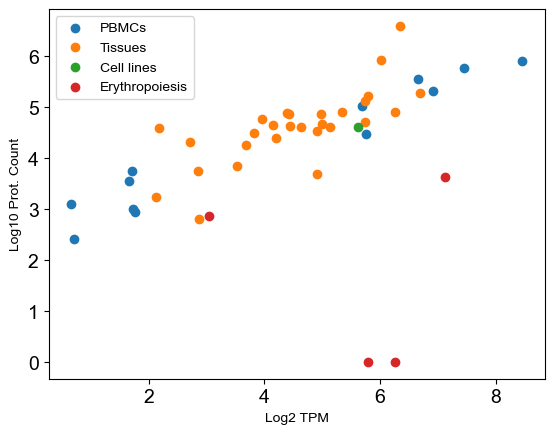

In [539]:
# Gene with good concordance on Intercept and Slope
gene = "IMPA2_HUMAN"
plt.scatter(df_PBMC.loc[df_PBMC["Gene"]==gene,"Log2 TPM"],df_PBMC.loc[df_PBMC["Gene"]==gene,"Log10 Prot. count"],label="PBMCs")
plt.scatter(df_tissues.loc[df_tissues["Gene"]==gene,"Log2 TPM"],df_tissues.loc[df_tissues["Gene"]==gene,"Log10 Prot. count"],label="Tissues")
plt.scatter(df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log2 TPM"],df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log10 Prot. count"],label="Cell lines")
plt.scatter(df_erythr.loc[df_erythr["Gene"]==gene,"Log2 TPM"],df_erythr.loc[df_erythr["Gene"]==gene,"Log10 Prot. count"],label="Erythropoiesis")
plt.legend()
plt.xlabel("Log2 TPM")
plt.ylabel("Log10 Prot. Count")

Text(0, 0.5, 'Log10 Prot. Count')

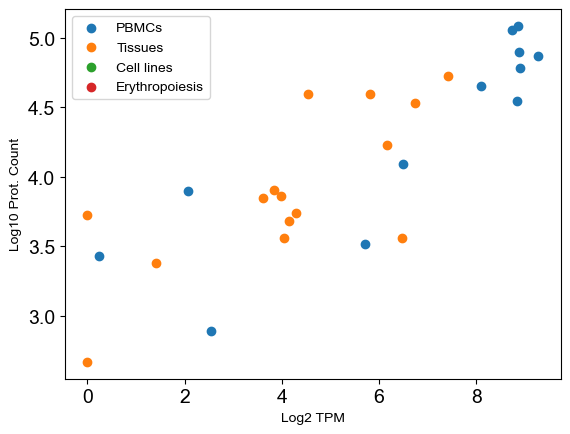

In [540]:
# Gene with good concordance on Intercept and Slope
gene = "CD2_HUMAN"df_lin_PBMC = parallel_gen_lin_model(df_PBMC, genes, 1, 24)
df_lin_tissues = parallel_gen_lin_model(df_tissues, genes, 1, 24)
plt.scatter(df_PBMC.loc[df_PBMC["Gene"]==gene,"Log2 TPM"],df_PBMC.loc[df_PBMC["Gene"]==gene,"Log10 Prot. count"],label="PBMCs")
plt.scatter(df_tissues.loc[df_tissues["Gene"]==gene,"Log2 TPM"],df_tissues.loc[df_tissues["Gene"]==gene,"Log10 Prot. count"],label="Tissues")
plt.scatter(df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log2 TPM"],df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log10 Prot. count"],label="Cell lines")
plt.scatter(df_erythr.loc[df_erythr["Gene"]==gene,"Log2 TPM"],df_erythr.loc[df_erythr["Gene"]==gene,"Log10 Prot. count"],label="Erythropoiesis")
plt.legend()
plt.xlabel("Log2 TPM")
plt.ylabel("Log10 Prot. Count")

Text(0, 0.5, 'Log10 Prot. Count')

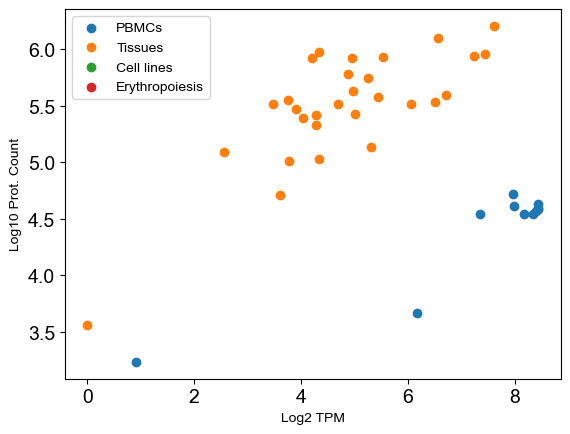

In [546]:
# Gene with good concordance on Slope only
gene = "GIMA4_HUMAN"
plt.scatter(df_PBMC.loc[df_PBMC["Gene"]==gene,"Log2 TPM"],df_PBMC.loc[df_PBMC["Gene"]==gene,"Log10 Prot. count"],label="PBMCs")
plt.scatter(df_tissues.loc[df_tissues["Gene"]==gene,"Log2 TPM"],df_tissues.loc[df_tissues["Gene"]==gene,"Log10 Prot. count"],label="Tissues")
plt.scatter(df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log2 TPM"],df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log10 Prot. count"],label="Cell lines")
plt.scatter(df_erythr.loc[df_erythr["Gene"]==gene,"Log2 TPM"],df_erythr.loc[df_erythr["Gene"]==gene,"Log10 Prot. count"],label="Erythropoiesis")
plt.legend()
plt.xlabel("Log2 TPM")
plt.ylabel("Log10 Prot. Count")

Text(0, 0.5, 'Log10 Prot. Count')

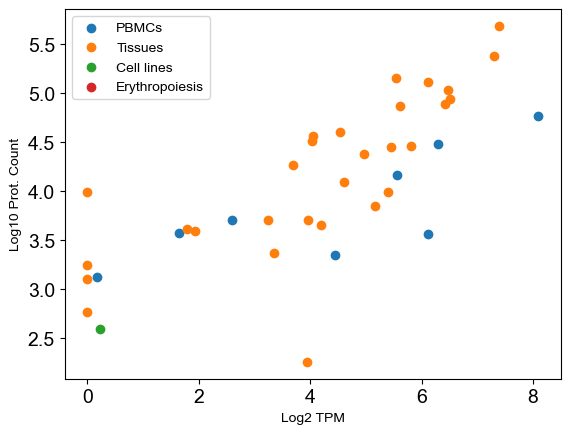

In [552]:
# Gene with good concordance on Intercept only (typically the slope is also close)
gene = "ST14_HUMAN"
plt.scatter(df_PBMC.loc[df_PBMC["Gene"]==gene,"Log2 TPM"],df_PBMC.loc[df_PBMC["Gene"]==gene,"Log10 Prot. count"],label="PBMCs")
plt.scatter(df_tissues.loc[df_tissues["Gene"]==gene,"Log2 TPM"],df_tissues.loc[df_tissues["Gene"]==gene,"Log10 Prot. count"],label="Tissues")
plt.scatter(df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log2 TPM"],df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log10 Prot. count"],label="Cell lines")
plt.scatter(df_erythr.loc[df_erythr["Gene"]==gene,"Log2 TPM"],df_erythr.loc[df_erythr["Gene"]==gene,"Log10 Prot. count"],label="Erythropoiesis")
plt.legend()
plt.xlabel("Log2 TPM")
plt.ylabel("Log10 Prot. Count")

Text(0, 0.5, 'Log10 Prot. Count')

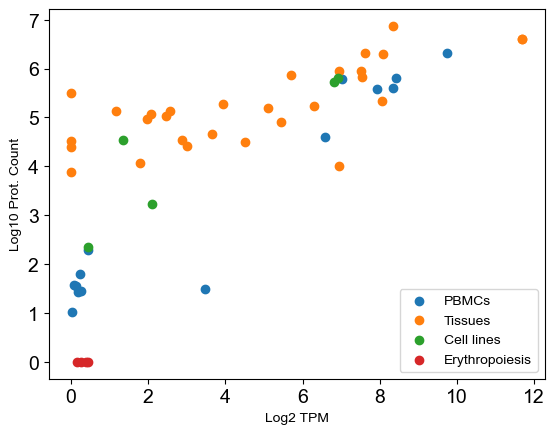

In [557]:
# Gene with bad concordance on Intercept and Slope
gene = "AMPN_HUMAN"
plt.scatter(df_PBMC.loc[df_PBMC["Gene"]==gene,"Log2 TPM"],df_PBMC.loc[df_PBMC["Gene"]==gene,"Log10 Prot. count"],label="PBMCs")
plt.scatter(df_tissues.loc[df_tissues["Gene"]==gene,"Log2 TPM"],df_tissues.loc[df_tissues["Gene"]==gene,"Log10 Prot. count"],label="Tissues")
plt.scatter(df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log2 TPM"],df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log10 Prot. count"],label="Cell lines")
plt.scatter(df_erythr.loc[df_erythr["Gene"]==gene,"Log2 TPM"],df_erythr.loc[df_erythr["Gene"]==gene,"Log10 Prot. count"],label="Erythropoiesis")
plt.legend()
plt.xlabel("Log2 TPM")
plt.ylabel("Log10 Prot. Count")

Text(0, 0.5, 'Log10 Prot. Count')

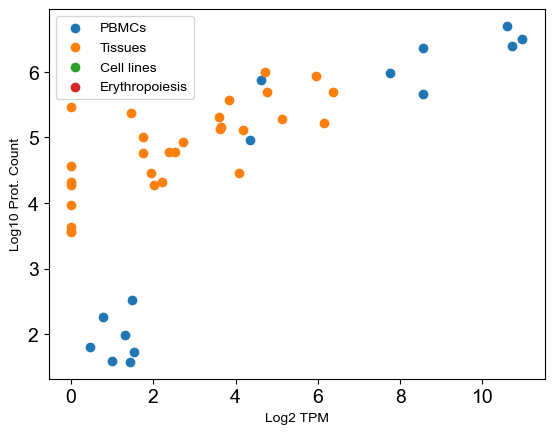

In [558]:
# Gene with bad concordance on Intercept and Slope
gene = "NCF1_HUMAN"
plt.scatter(df_PBMC.loc[df_PBMC["Gene"]==gene,"Log2 TPM"],df_PBMC.loc[df_PBMC["Gene"]==gene,"Log10 Prot. count"],label="PBMCs")
plt.scatter(df_tissues.loc[df_tissues["Gene"]==gene,"Log2 TPM"],df_tissues.loc[df_tissues["Gene"]==gene,"Log10 Prot. count"],label="Tissues")
plt.scatter(df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log2 TPM"],df_cell_lines.loc[df_cell_lines["Gene"]==gene,"Log10 Prot. count"],label="Cell lines")
plt.scatter(df_erythr.loc[df_erythr["Gene"]==gene,"Log2 TPM"],df_erythr.loc[df_erythr["Gene"]==gene,"Log10 Prot. count"],label="Erythropoiesis")
plt.legend()
plt.xlabel("Log2 TPM")
plt.ylabel("Log10 Prot. Count")

In [ ]:
# get "dist" mat of slope/intercept with or without a dataset

In [1081]:
df = pd.read_csv('results/model_perf/lin_model_cell.tsv.gz', sep='\t')

In [1083]:
df["Dataset"].drop_duplicates()

0                       linear_immune_train
1303               linear_immune_validation
1500             linear_immune_test_tissues
4400          linear_immune_test_cell_lines
5200      linear_immune_test_erythropoiesis
5600                   linear_tissues_train
8208              linear_tissues_validation
8500             linear_tissues_test_immune
10000        linear_tissues_test_cell_lines
10800    linear_tissues_test_erythropoiesis
Name: Dataset, dtype: object

In [1094]:
df.loc[df["Dataset"]=="linear_tissues_test_cell_lines"].groupby("Cell")[["MAE","Spearman prediction","Spearman RNA"]].mean().loc[["ACH-000364","ACH-000232","ACH-001328"]].mean()

MAE                    1.023267
Spearman prediction    0.516178
Spearman RNA           0.485700
dtype: float64

In [1095]:
df.loc[df["Dataset"]=="linear_tissues_test_cell_lines"].groupby("Cell")[["MAE","Spearman prediction","Spearman RNA"]].mean().loc[['ACH-000075','ACH-000090','ACH-000681','ACH-000739','ACH-001086']].mean()

MAE                    0.710605
Spearman prediction    0.603355
Spearman RNA           0.645211
dtype: float64

In [1077]:
df_lin["Gene"].drop_duplicates()

0       NEIL1_HUMAN
1       LTBP4_HUMAN
2       TMED8_HUMAN
3        KLC2_HUMAN
4       DHX30_HUMAN
           ...     
3496     RTCB_HUMAN
3497    DJC30_HUMAN
3498    AIMP2_HUMAN
3499    S38A2_HUMAN
3500    ERG24_HUMAN
Name: Gene, Length: 3501, dtype: object

In [1078]:
df_lin2["Gene"].drop_duplicates()

0       KIF11_HUMAN
1       GSDMB_HUMAN
2       RHG44_HUMAN
3       HUWE1_HUMAN
4       ZFY16_HUMAN
           ...     
4662     LDLR_HUMAN
4663    AGRE5_HUMAN
4664    NHSL2_HUMAN
4665     F13B_HUMAN
4666    KATL1_HUMAN
Name: Gene, Length: 4667, dtype: object

In [1076]:
df_lin = pd.read_csv('results/lin_model/linear_immune.tsv.gz', sep='\t')
df_lin2 = pd.read_csv('results/lin_model/linear_tissues.tsv.gz', sep='\t')
common_genes_DE = list(set(df_lin["Gene"].drop_duplicates()) & set(df_lin2["Gene"].drop_duplicates()))

In [813]:
df_PBMC = pd.read_csv("data/PBMCs_dataset.csv").dropna()
df_PBMC = df_PBMC.loc[df_PBMC["Gene"].isin(common_genes_DE)]
df_PBMC["Sample"] = 0
df_tissues = pd.read_csv("data/tissues_dataset.csv").dropna()
df_tissues = df_tissues.loc[df_tissues["Gene"].isin(common_genes_DE)]
df_tissues["Sample"] = 0

In [814]:
df_lin_PBMC = parallel_gen_lin_model(df_PBMC, common_genes_DE, 1, 24)
df_lin_tissues = parallel_gen_lin_model(df_tissues, common_genes_DE, 1, 24)

In [815]:
df_lin_PBMC_tissuesc = df_lin_PBMC_tissues.copy()

In [816]:
tissues_cells = [df_tissues["Cell"].sample(n=15).values for i in range(0,20)]
df_join = pd.DataFrame()
for i in range(0,20):
    df_sample = pd.concat([df_PBMC,df_tissues.loc[df_tissues["Cell"].isin(tissues_cells[i])]])
    df_sample["Sample"] = i
    df_join = pd.concat([df_join,df_sample])
df_lin_PBMC_tissues = parallel_gen_lin_model(df_join, common_genes_DE, 20, 24)
df_lin_PBMC_tissues = df_lin_PBMC_tissues.groupby("Gene").mean()

In [817]:
np.mean(np.abs((df_lin_PBMC["Intercept"].values-df_lin_PBMC_tissues.loc[df_lin_PBMC["Gene"].values]["Intercept"]).values))

0.5563951533415951

In [818]:
np.mean(np.abs((df_lin_tissues["Intercept"].values-df_lin_PBMC_tissues.loc[df_lin_tissues["Gene"].values]["Intercept"]).values))

0.6280467315761659

In [819]:
np.mean(np.abs((df_lin_PBMC["Slope"].values-df_lin_PBMC_tissues.loc[df_lin_PBMC["Gene"].values]["Slope"]).values))

0.13333949924530142

In [820]:
np.mean(np.abs((df_lin_tissues["Slope"].values-df_lin_PBMC_tissues.loc[df_lin_tissues["Gene"].values]["Slope"]).values))

0.11712176990603577

In [ ]:
# The same but also for the other datasets

In [1134]:
df_PBMC = pd.read_csv("data/PBMCs_dataset.csv").dropna()
df_tissues = pd.read_csv("data/tissues_dataset.csv").dropna()
df_lin = pd.read_csv('results/lin_model/linear_immune.tsv.gz', sep='\t')
df_PBMC = df_PBMC.loc[df_PBMC["Gene"].isin(df_lin["Gene"].drop_duplicates())]
df_tissues = df_tissues.loc[df_tissues["Gene"].isin(df_lin["Gene"].drop_duplicates())]

In [1112]:
corr = scc_per_gene(df_PBMC, df_lin["Gene"].drop_duplicates(), min_cells=3)

In [1122]:
best = corr.sort_values().tail(351).index

In [1123]:
best

Index(['TM9S2_HUMAN', 'TPD54_HUMAN', 'F16P1_HUMAN', 'STX7_HUMAN',
       'DHRS7_HUMAN', 'DHRS9_HUMAN', 'PGH1_HUMAN', 'CD99_HUMAN', 'ATRAP_HUMAN',
       'MGST2_HUMAN',
       ...
       'AGRE3_HUMAN', 'BAG3_HUMAN', 'UB2J1_HUMAN', 'LRRK2_HUMAN', 'HCK_HUMAN',
       'CPPED_HUMAN', 'HYES_HUMAN', 'AL3B1_HUMAN', 'PGRP1_HUMAN',
       'MPRD_HUMAN'],
      dtype='object', name='Gene', length=351)

In [1141]:
df_tissues.loc[df_tissues["Gene"].isin(best),"Log2 TPM"].var()

5.716275283765351

In [1142]:
df_tissues.loc[~df_tissues["Gene"].isin(best),"Log2 TPM"].var()

4.6733708708050665

In [822]:
df_PBMC = pd.read_csv("data/PBMCs_dataset.csv").dropna()
df_PBMC = df_PBMC.loc[df_PBMC["Gene"].isin(genes)]
df_PBMC["Sample"] = 0
df_tissues = pd.read_csv("data/tissues_dataset.csv").dropna()
df_tissues = df_tissues.loc[df_tissues["Gene"].isin(genes)]
df_tissues["Sample"] = 0
df_cell_lines = pd.read_csv("data/cell_lines_dataset.csv").dropna()
df_cell_lines = df_cell_lines.loc[df_cell_lines["Gene"].isin(genes)]
df_cell_lines["Sample"] = 0
df_erythr = pd.read_csv("data/erythropoiesis_dataset.csv").dropna()
df_erythr = df_erythr.loc[df_erythr["Gene"].isin(genes)]
df_erythr["Sample"] = 0

In [825]:
tissues_cells = [df_tissues["Cell"].sample(n=4).values for i in range(0,30)]
df_join = pd.DataFrame()
for i in range(0,30):
    df_sample = pd.concat([df_PBMC,df_tissues.loc[df_tissues["Cell"].isin(tissues_cells[i])]])
    df_sample["Sample"] = i
    df_join = pd.concat([df_join,df_sample])
df_lin_PBMC_tissues = parallel_gen_lin_model(df_join, genes, 30, 24)
df_lin_PBMC_tissues = df_lin_PBMC_tissues.groupby("Gene").mean()

In [837]:
cell_lines_cells = [df_cell_lines["Cell"].sample(n=4).values for i in range(0,30)]
df_join = pd.DataFrame()
for i in range(0,30):
    df_sample = pd.concat([df_PBMC,df_cell_lines.loc[df_cell_lines["Cell"].isin(cell_lines_cells[i])]])
    df_sample["Sample"] = i
    df_join = pd.concat([df_join,df_sample])
df_lin_PBMC_cell_lines = parallel_gen_lin_model(df_join, genes, 30, 24)
df_lin_PBMC_cell_lines = df_lin_PBMC_cell_lines.groupby("Gene").mean()

In [828]:
df_lin_PBMC = parallel_gen_lin_model(df_PBMC, genes, 1, 24)
df_lin_PBMC_eythr = parallel_gen_lin_model(pd.concat([df_PBMC,df_erythr]), genes, 1, 24)

In [849]:
np.mean(np.abs((df_lin_PBMC["Intercept"].values-df_lin_PBMC_tissues.loc[df_lin_PBMC["Gene"].values]["Intercept"]).values))/df_lin_PBMC["Intercept"].mean()

0.08094956506427999

In [850]:
np.mean(np.abs((df_lin_PBMC["Intercept"].values-df_lin_PBMC_cell_lines.loc[df_lin_PBMC["Gene"].values]["Intercept"]).values))/df_lin_PBMC["Intercept"].mean()

0.054582051731251476

In [851]:
np.mean(np.abs((df_lin_PBMC["Intercept"].values-df_lin_PBMC_eythr["Intercept"]).values))/df_lin_PBMC["Intercept"].mean()

0.14935348586291314

In [843]:
np.mean(np.abs((df_lin_PBMC["Slope"].values-df_lin_PBMC_tissues.loc[df_lin_PBMC["Gene"].values]["Slope"]).values))/df_lin_PBMC["Slope"].mean()

0.41739644107670976

In [844]:
np.mean(np.abs((df_lin_PBMC["Slope"].values-df_lin_PBMC_cell_lines.loc[df_lin_PBMC["Gene"].values]["Slope"]).values))/df_lin_PBMC["Slope"].mean()

0.32622290163875606

In [866]:
np.mean(np.abs((df_lin_PBMC["Slope"].values-df_lin_PBMC_eythr["Slope"]).values))/df_lin_PBMC["Slope"].mean()

0.743038875497311

In [856]:
df_lin_tissues = parallel_gen_lin_model(df_tissues, genes, 1, 24)
df_lin_tissues_eythr = parallel_gen_lin_model(pd.concat([df_tissues,df_erythr]), genes, 1, 24)

In [858]:
PBMC_cells = [df_PBMC["Cell"].sample(n=4).values for i in range(0,30)]
df_join = pd.DataFrame()
for i in range(0,30):
    df_sample = pd.concat([df_tissues,df_PBMC.loc[df_PBMC["Cell"].isin(PBMC_cells[i])]])
    df_sample["Sample"] = i
    df_join = pd.concat([df_join,df_sample])
df_lin_tissues_PBMC = parallel_gen_lin_model(df_join, genes, 30, 24)
df_lin_tissues_PBMC = df_lin_PBMC_tissues.groupby("Gene").mean()

In [859]:
df_join = pd.DataFrame()
for i in range(0,30):
    df_sample = pd.concat([df_tissues,df_cell_lines.loc[df_cell_lines["Cell"].isin(cell_lines_cells[i])]])
    df_sample["Sample"] = i
    df_join = pd.concat([df_join,df_sample])
df_lin_tissues_cell_lines = parallel_gen_lin_model(df_join, genes, 30, 24)
df_lin_tissues_cell_lines = df_lin_tissues_cell_lines.groupby("Gene").mean()

In [861]:
np.mean(np.abs((df_lin_tissues["Intercept"].values-df_lin_tissues_PBMC.loc[df_lin_tissues["Gene"].values]["Intercept"]).values))/df_lin_tissues["Intercept"].mean()

0.20656013984231247

In [862]:
np.mean(np.abs((df_lin_tissues["Intercept"].values-df_lin_tissues_cell_lines.loc[df_lin_tissues["Gene"].values]["Intercept"]).values))/df_lin_tissues["Intercept"].mean()

0.01990057191349991

In [867]:
np.mean(np.abs((df_lin_tissues["Intercept"].values-df_lin_PBMC_eythr["Intercept"]).values))/df_lin_tissues["Intercept"].mean()

0.2874717447042457

In [871]:
np.mean(np.abs((df_lin_tissues["Slope"].values-df_lin_tissues_PBMC.loc[df_lin_tissues["Gene"].values]["Slope"]).values))/df_lin_tissues["Slope"].mean()

1.0313092894306004

In [870]:
np.mean(np.abs((df_lin_tissues["Slope"].values-df_lin_tissues_cell_lines.loc[df_lin_tissues["Gene"].values]["Slope"]).values))/df_lin_tissues["Slope"].mean()

0.129688505348423

In [872]:
np.mean(np.abs((df_lin_tissues["Slope"].values-df_lin_PBMC_eythr["Slope"]).values))/df_lin_tissues["Slope"].mean()

1.4418529067814483